In [1]:
# ===== CELL 1: SETUP & KIỂM TRA ĐẦU VÀO =====
import os, json, random
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Đường dẫn (khớp cấu trúc blueprint)
ROOT        = '/content/drive/MyDrive/flower-multilabel-project'
RAW_DIR     = f'{ROOT}/data/raw'
META_DIR    = f'{ROOT}/data/metadata'
MODEL_PATH  = f'{ROOT}/models/final/flower_singlelabel_model.keras'
CLASSES_JSON = f'{META_DIR}/classes.json'
SPLIT_CSV    = f'{META_DIR}/singlelabel_split.csv'

# Thư mục MỚI cho notebook 07 (cần ghi vào blueprint v4)
OOD_DIR     = f'{ROOT}/data/ood'          # ảnh OOD + ood_split.csv
OOD_OUT_DIR = f'{ROOT}/models/ood'        # cache logit/feature, ood_config.json, kết quả
for d in [OOD_DIR, OOD_OUT_DIR]:
    os.makedirs(d, exist_ok=True)

# 3. Hằng số dùng chung cho cả notebook
SEED = 42
IMG_SIZE = 224
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# 4. Nạp classes.json
with open(CLASSES_JSON, encoding='utf-8') as f:
    classes_raw = json.load(f)
print('Kiểu dữ liệu classes.json:', type(classes_raw))
print(classes_raw if len(str(classes_raw)) < 1500 else str(classes_raw)[:1500])

# 5. Nạp model đơn nhãn (không cần compile vì chỉ suy luận)
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
print('\nInput shape :', model.input_shape)
print('Output shape:', model.output_shape)
print('Layer cuối  :', model.layers[-1].name, '| activation =',
      getattr(model.layers[-1], 'activation', None).__name__)
print('Số layer    :', len(model.layers))

# Xác nhận preprocess_input đã nhúng trong model (như đã thấy ở Tuần 4)
for l in model.layers[:6]:
    print('  ', l.name, '->', l.__class__.__name__)

# 6. Kiểm tra softmax: ảnh ngẫu nhiên 0-255, tổng xác suất phải ≈ 1
dummy = np.random.randint(0, 256, (4, IMG_SIZE, IMG_SIZE, 3)).astype('float32')
p = model.predict(dummy, verbose=0)
print('\nTổng xác suất mỗi ảnh:', p.sum(axis=1).round(4))

# 7. Nạp split cũ của model đơn nhãn
split_df = pd.read_csv(SPLIT_CSV)
print('\nCột của singlelabel_split.csv:', list(split_df.columns))
print(split_df.head(3))
print('Kích thước:', split_df.shape)

# 8. Đếm ảnh raw theo lớp (đối chiếu 5.010 ảnh)
counts = {d: len(os.listdir(f'{RAW_DIR}/{d}')) for d in sorted(os.listdir(RAW_DIR))
          if os.path.isdir(f'{RAW_DIR}/{d}')}
print('\nSố ảnh raw theo lớp:', counts)
print('Tổng:', sum(counts.values()))

Mounted at /content/drive
Kiểu dữ liệu classes.json: <class 'list'>
[{'index': 0, 'id': 'hoa_hong', 'name': 'Hoa Hồng'}, {'index': 1, 'id': 'hoa_huong_duong', 'name': 'Hoa Hướng Dương'}, {'index': 2, 'id': 'hoa_cuc', 'name': 'Hoa Cúc'}, {'index': 3, 'id': 'hoa_tulip', 'name': 'Hoa Tulip'}, {'index': 4, 'id': 'hoa_bo_cong_anh', 'name': 'Bồ Công Anh'}, {'index': 5, 'id': 'hoa_sen', 'name': 'Hoa Sen'}, {'index': 6, 'id': 'hoa_lan', 'name': 'Hoa Lan'}, {'index': 7, 'id': 'hoa_mai', 'name': 'Hoa Mai'}, {'index': 8, 'id': 'hoa_dao', 'name': 'Hoa Đào'}, {'index': 9, 'id': 'hoa_oai_huong', 'name': 'Oải Hương'}]

Input shape : (None, 224, 224, 3)
Output shape: (None, 10)
Layer cuối  : dense_1 | activation = softmax
Số layer    : 6
   input_layer_1 -> InputLayer
   densenet121 -> Functional
   global_average_pooling2d -> GlobalAveragePooling2D
   dense -> Dense
   dropout -> Dropout
   dense_1 -> Dense

Tổng xác suất mỗi ảnh: [1. 1. 1. 1.]

Cột của singlelabel_split.csv: ['path', 'label', 'class

In [2]:
# ===== CELL 1b: HẰNG SỐ + KIỂM TRA NHẤT QUÁN =====
# 1. Hằng số lớp (sắp theo 'index' để chắc chắn đúng thứ tự cố định CON-05)
classes_sorted = sorted(classes_raw, key=lambda c: c['index'])
CLASS_IDS   = [c['id'] for c in classes_sorted]
CLASS_NAMES = {c['id']: c['name'] for c in classes_sorted}
ID2IDX      = {cid: i for i, cid in enumerate(CLASS_IDS)}
NUM_CLASSES = len(CLASS_IDS)
assert [c['index'] for c in classes_sorted] == list(range(10)), 'index trong classes.json không liên tục 0-9'

# 2. Cột label trong split phải khớp classes.json
assert (split_df['label'] == split_df['class_id'].map(ID2IDX)).all(), 'label KHÔNG khớp classes.json!'
print('✓ label trong split khớp thứ tự classes.json')

# 3. Kích thước 3 tập (kỳ vọng 3507 / 751 / 752)
print('\nSố ảnh theo tập:\n', split_df['split'].value_counts())

# 4. Mọi đường dẫn trong split đều tồn tại?
missing = [p for p in split_df['path'] if not os.path.exists(p)]
print(f'\nĐường dẫn không tồn tại: {len(missing)}/{len(split_df)}')
if missing: print(missing[:3])

# 5. Tìm 3 file nằm trong data/raw nhưng không thuộc split nào
in_split = set(zip(split_df['class_id'], split_df['path'].map(os.path.basename)))
extra = []
for cid in CLASS_IDS:
    for fn in os.listdir(f'{RAW_DIR}/{cid}'):
        if (cid, fn) not in in_split:
            extra.append((cid, fn))
print(f'\nFile có trong raw nhưng KHÔNG nằm trong split: {len(extra)}')
for e in extra: print('  ', e)

# 6. Xác nhận preprocess nằm trong densenet121 lồng bên trong
base = model.get_layer('densenet121')
print('\n5 layer đầu của densenet121:', [(l.name, l.__class__.__name__) for l in base.layers[:5]])

✓ label trong split khớp thứ tự classes.json

Số ảnh theo tập:
 split
train    3507
test      752
val       751
Name: count, dtype: int64

Đường dẫn không tồn tại: 0/5010

File có trong raw nhưng KHÔNG nằm trong split: 3
   ('hoa_dao', 'hoa_dao_0163.2023')
   ('hoa_oai_huong', 'Lavender haze_..  www.movedbyinspiratoin.com')
   ('hoa_oai_huong', '37K views · 16K reactions _ Multi-colored flower field of Farm Tomita in Furano city in Hokkaido_ This is the beautiful scenery we can see soon. Furano city is a very famous place as the lave _ 1…')

5 layer đầu của densenet121: [('input_layer', 'InputLayer'), ('zero_padding2d', 'ZeroPadding2D'), ('conv1_conv', 'Conv2D'), ('conv1_bn', 'BatchNormalization'), ('conv1_relu', 'Activation')]


In [3]:
# ===== CELL 1c: XÁC ĐỊNH CHUẨN HÓA PIXEL ĐÚNG =====
from PIL import Image
from tensorflow.keras.applications.densenet import preprocess_input as dn_pre

def load_square(path, size=IMG_SIZE):
    """Cắt vuông giữa rồi resize (giống backend)."""
    img = Image.open(path).convert('RGB')
    w, h = img.size; s = min(w, h)
    l, t = (w - s) // 2, (h - s) // 2
    img = img.crop((l, t, l + s, t + s)).resize((size, size), Image.BILINEAR)
    return np.asarray(img, dtype='float32')          # thang [0, 255]

val_sample = split_df[split_df['split'] == 'val'].sample(300, random_state=SEED)
X = np.stack([load_square(p) for p in val_sample['path']])
y = val_sample['label'].values
print('X:', X.shape, '| min/max:', X.min(), X.max())

options = {
    'A. raw [0,255]'              : lambda a: a.copy(),
    'B. chia 255 -> [0,1]'        : lambda a: a / 255.0,
    'C. densenet.preprocess_input': lambda a: dn_pre(a.copy()),
}
for name, fx in options.items():
    p = model.predict(fx(X), batch_size=32, verbose=0)
    acc = (p.argmax(1) == y).mean()
    print(f'{name:32s} acc = {acc:.4f} | max-prob trung bình = {p.max(1).mean():.3f}')

X: (300, 224, 224, 3) | min/max: 0.0 255.0
A. raw [0,255]                   acc = 0.9333 | max-prob trung bình = 0.947
B. chia 255 -> [0,1]             acc = 0.1967 | max-prob trung bình = 0.370
C. densenet.preprocess_input     acc = 0.3600 | max-prob trung bình = 0.422


In [4]:
# ===== CELL 2a: TẢI OXFORD 102 + CONTACT SHEET =====
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.datasets import Flowers102

OX_DIR = '/content/oxford102'   # lưu tạm trên Colab, không cần Drive
ox_sets = [Flowers102(root=OX_DIR, split=s, download=True) for s in ['train', 'val', 'test']]

# Gom đường dẫn + nhãn của cả 3 split (tổng 8189 ảnh)
ox_files  = [f for ds in ox_sets for f in ds._image_files]
ox_labels = [l for ds in ox_sets for l in ds._labels]
ox_df = pd.DataFrame({'path': [str(f) for f in ox_files], 'ox_label': ox_labels})
print('Tổng ảnh Oxford:', len(ox_df), '| số lớp:', ox_df['ox_label'].nunique())

# Contact sheet: 1 ảnh mẫu / lớp, chia 2 hình cho dễ nhìn
def show_sheet(label_range, cols=9):
    labels = list(label_range)
    rows = int(np.ceil(len(labels) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    for ax in axes.ravel(): ax.axis('off')
    for ax, lb in zip(axes.ravel(), labels):
        p = ox_df[ox_df['ox_label'] == lb]['path'].iloc[0]
        ax.imshow(Image.open(p).convert('RGB').resize((160, 160)))
        ax.set_title(f'#{lb}', fontsize=11, fontweight='bold')
    plt.tight_layout(); plt.show()

show_sheet(range(0, 51))
show_sheet(range(51, 102))

Output hidden; open in https://colab.research.google.com to view.

In [5]:
from concurrent.futures import ThreadPoolExecutor

In [6]:
# ===== CELL 2b: DỰNG TẬP OOD HOA LẠ =====
# 1. Danh sách loại trừ (bạn đã chốt) + bổ sung nếu thấy thiếu (tulip, súng...)
EXCLUDE = {1, 4, 6, 9, 13, 16, 40, 48, 49, 53, 58, 62, 65, 69, 70, 72, 73, 77, 99}
# EXCLUDE |= {88, 72}   # <- bỏ comment SAU KHI đối chiếu đúng chỉ số trên contact sheet

# Nhóm "hard": lớp KHÁC LOÀI nhưng giống ID, chỉ để báo cáo stress test (mặc định rỗng)
HARD_OOD_LABELS = set()   # ví dụ: {48}. Không đặt lớp thực sự là cùng loài với 10 lớp ID

N_TEST_CLASSES = 30       # số lớp chỉ xuất hiện ở test (loài chưa từng thấy lúc chọn tham số)
N_PER_CLASS    = 8        # tối đa ảnh lấy mỗi lớp

all_labels = sorted(ox_df['ox_label'].unique())
cand_labels = [l for l in all_labels if l not in EXCLUDE and l not in HARD_OOD_LABELS]
print(f'Lớp Oxford: {len(all_labels)} | loại trừ: {len(EXCLUDE)} | hard: {len(HARD_OOD_LABELS)} | dùng làm OOD: {len(cand_labels)}')

# 2. Tách theo LỚP (không theo ảnh): lớp nào ở val thì không xuất hiện ở test
rng = np.random.RandomState(SEED)
shuffled = rng.permutation(cand_labels).tolist()
test_cls = set(shuffled[:N_TEST_CLASSES])
val_cls  = set(shuffled[N_TEST_CLASSES:])

rows = []
for lb in cand_labels:
    sub = ox_df[ox_df['ox_label'] == lb]
    sub = sub.sample(min(N_PER_CLASS, len(sub)), random_state=SEED)
    for p in sub['path']:
        rows.append({'path': p, 'ox_label': lb, 'ood_type': 'near_flower',
                     'split': 'test' if lb in test_cls else 'val'})
for lb in sorted(HARD_OOD_LABELS):
    sub = ox_df[ox_df['ox_label'] == lb].sample(min(N_PER_CLASS, (ox_df['ox_label'] == lb).sum()), random_state=SEED)
    for p in sub['path']:
        rows.append({'path': p, 'ox_label': lb, 'ood_type': 'near_flower_hard', 'split': 'report_only'})
flower_ood = pd.DataFrame(rows)
print(flower_ood.groupby(['ood_type', 'split']).size())
assert not (set(flower_ood[flower_ood.split=='val'].ox_label) & set(flower_ood[flower_ood.split=='test'].ox_label)), 'Lớp bị lẫn giữa val và test!'

# 3. Kiểm tra trùng ảnh với tập ID bằng dHash (đối phó việc ảnh bị resize/lưu lại)
def dhash_bytes(path):
    img = Image.open(path).convert('L').resize((9, 8), Image.BILINEAR)
    a = np.asarray(img, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())        # 8 byte

def dhash_many(paths, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return np.stack(list(ex.map(dhash_bytes, paths)))

ID_HASH_FILE = f'{OOD_OUT_DIR}/id_dhash.npy'
if os.path.exists(ID_HASH_FILE):
    id_h = np.load(ID_HASH_FILE)
else:
    id_h = dhash_many(split_df['path'].tolist()); np.save(ID_HASH_FILE, id_h)
ood_h = dhash_many(flower_ood['path'].tolist())

POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
dist_min = np.empty(len(ood_h), dtype=np.int32)
for i in range(len(ood_h)):                                   # (N,8) XOR (8,) -> popcount
    dist_min[i] = POP[np.bitwise_xor(id_h, ood_h[i])].sum(axis=1).min()
flower_ood['min_hash_dist'] = dist_min
dup = flower_ood['min_hash_dist'] <= 6
print(f'\nẢnh OOD nghi trùng với ID (khoảng cách hash ≤ 6): {dup.sum()}/{len(flower_ood)}')
print(flower_ood[dup][['ox_label', 'split', 'min_hash_dist']].head(10))
flower_ood = flower_ood[~dup].reset_index(drop=True)

# 4. Lưu
flower_ood.to_csv(f'{OOD_DIR}/ood_flower_split.csv', index=False)
print('\nĐã lưu ood_flower_split.csv:', flower_ood['split'].value_counts().to_dict())

Lớp Oxford: 102 | loại trừ: 19 | hard: 0 | dùng làm OOD: 83
ood_type     split
near_flower  test     240
             val      424
dtype: int64

Ảnh OOD nghi trùng với ID (khoảng cách hash ≤ 6): 12/664
     ox_label split  min_hash_dist
7           0  test              6
65         12   val              5
66         12   val              6
109        19   val              4
148        24  test              6
153        25   val              6
156        25   val              6
220        33   val              2
432        67   val              6
490        79  test              5

Đã lưu ood_flower_split.csv: {'val': 416, 'test': 236}


Số cặp nghi trùng: 12


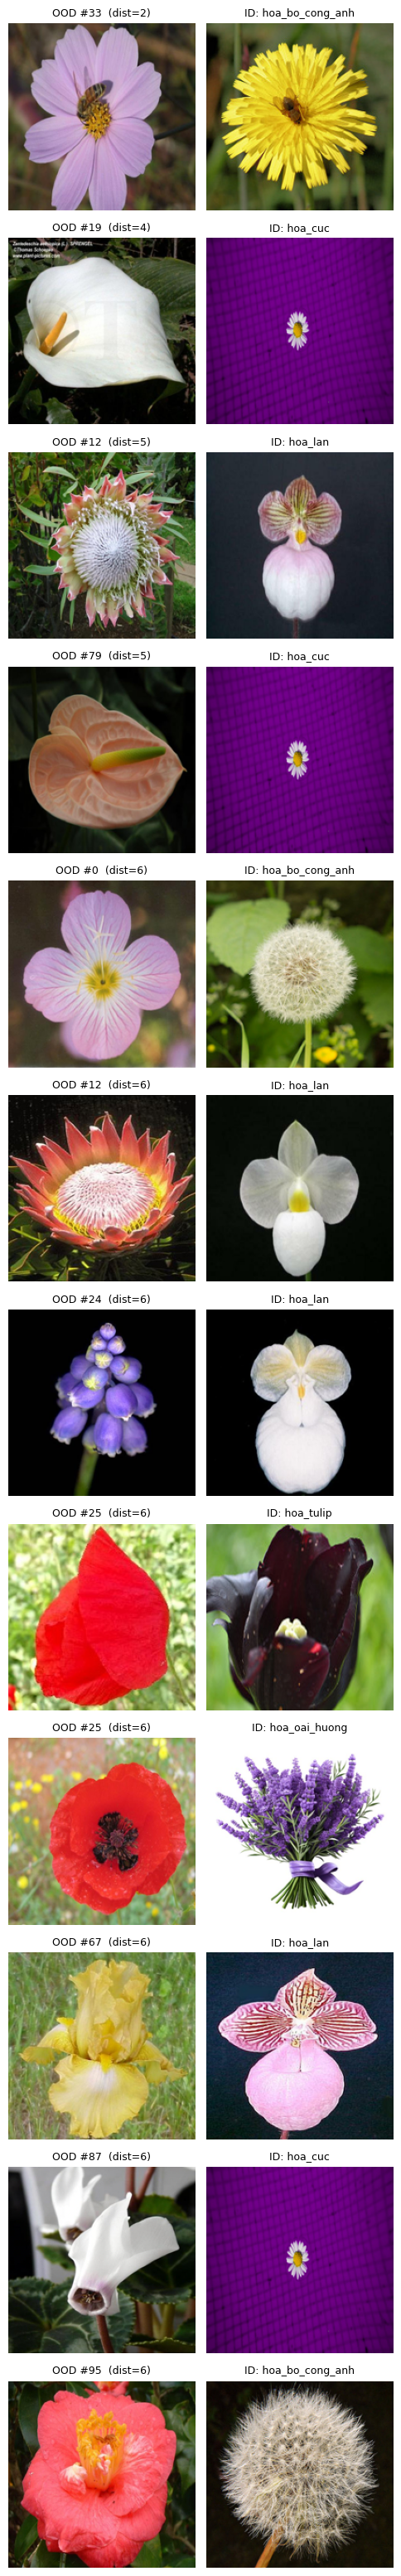

In [7]:
# ===== CELL 2b-check (TÙY CHỌN): XEM CẶP ẢNH NGHI TRÙNG =====
# Cần chạy lại phần tạo flower_ood TRƯỚC khi lọc trùng, nên dựng lại bảng đầy đủ:
full = pd.read_csv(f'{OOD_DIR}/ood_flower_split.csv')   # đã lọc rồi -> không có ảnh nghi trùng
# => dựng lại từ ox_df giống Cell 2b nhưng KHÔNG lọc:
rows = []
rng = np.random.RandomState(SEED)
for lb in cand_labels:
    sub = ox_df[ox_df['ox_label'] == lb].sample(min(N_PER_CLASS, (ox_df['ox_label'] == lb).sum()), random_state=SEED)
    rows += [{'path': p, 'ox_label': lb} for p in sub['path']]
unf = pd.DataFrame(rows)
unf_h = dhash_many(unf['path'].tolist())

hits = []
for i in range(len(unf_h)):
    d = POP[np.bitwise_xor(id_h, unf_h[i])].sum(axis=1)
    j = d.argmin()
    if d[j] <= 6: hits.append((i, j, int(d[j])))
hits.sort(key=lambda t: t[2])
print('Số cặp nghi trùng:', len(hits))

fig, axes = plt.subplots(len(hits), 2, figsize=(5, 2.6 * len(hits)))
for r, (i, j, d) in enumerate(hits):
    axes[r, 0].imshow(Image.open(unf['path'].iloc[i]).convert('RGB').resize((200, 200)))
    axes[r, 0].set_title(f'OOD #{unf["ox_label"].iloc[i]}  (dist={d})', fontsize=9)
    axes[r, 1].imshow(Image.open(split_df['path'].iloc[j]).convert('RGB').resize((200, 200)))
    axes[r, 1].set_title(f'ID: {split_df["class_id"].iloc[j]}', fontsize=9)
    for a in axes[r]: a.axis('off')
plt.tight_layout(); plt.show()

In [8]:
# ===== CELL 2c: NHÓM KHÔNG PHẢI HOA (FAR-OOD) — BẢN HOÀN CHỈNH =====
import re
from torchvision.datasets import DTD, OxfordIIITPet

NF_SRC  = '/content/nonflower_src'      # nơi tải tạm trên Colab
OWN_DIR = f'{OOD_DIR}/non_flower'       # ảnh riêng: la_01.jpg, co_02.jpg, ...
N_DTD_PER_CLASS = 5
N_PET_PER_CLASS = 3
VAL_CLASS_FRAC  = 0.65
rng = np.random.RandomState(SEED)       # dùng tuần tự: DTD -> Pets -> ảnh riêng (giữ nguyên thứ tự để tái lập)

# ---------- Hàm dùng chung ----------
def collect(ds_list, source):
    classes = ds_list[0].classes
    files, labels = [], []
    for ds in ds_list:
        fs = getattr(ds, '_image_files', None) or getattr(ds, '_images')
        files  += [str(f) for f in fs]
        labels += list(ds._labels)
    return pd.DataFrame({'path': files, 'cls': [classes[l] for l in labels], 'source': source})

def cap_per_class(df, n):
    parts_ = [g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby('cls')]
    return pd.concat(parts_, ignore_index=True)

def split_by_class(df):
    """Chia val/test theo LỚP/NHÓM: cùng lớp luôn nằm cùng một tập."""
    cls = rng.permutation(sorted(df['cls'].unique())).tolist()
    val_set = set(cls[:int(round(VAL_CLASS_FRAC * len(cls)))])
    df = df.copy()
    df['split'] = np.where(df['cls'].isin(val_set), 'val', 'test')
    return df

def upsert(csv_path, new_df, cols, drop_type):
    """Thay toàn bộ dòng có ood_type = drop_type bằng new_df (chạy lại nhiều lần vẫn an toàn)."""
    old = pd.read_csv(csv_path) if os.path.exists(csv_path) else pd.DataFrame(columns=cols)
    old = old[old['ood_type'] != drop_type]
    pd.concat([old, new_df[cols]], ignore_index=True).to_csv(csv_path, index=False)

parts = []

# ---------- 1. DTD: kết cấu (bỏ lớp 'flowery' vì chứa hoa) ----------
dtd = collect([DTD(NF_SRC, split=s, download=True) for s in ['train', 'val', 'test']], 'dtd')
print('DTD:', len(dtd), 'ảnh,', dtd['cls'].nunique(), 'lớp')
dtd = dtd[dtd['cls'] != 'flowery']
dtd = split_by_class(cap_per_class(dtd, N_DTD_PER_CLASS))
dtd['ood_type'] = 'far_texture'
parts.append(dtd)

# ---------- 2. Oxford-IIIT Pet: động vật ----------
pets = collect([OxfordIIITPet(NF_SRC, split=s, download=True) for s in ['trainval', 'test']], 'pets')
print('Pets:', len(pets), 'ảnh,', pets['cls'].nunique(), 'lớp')
pets = split_by_class(cap_per_class(pets, N_PET_PER_CLASS))
pets['ood_type'] = 'far_animal'
parts.append(pets)

# ---------- 3. Ảnh riêng: nhóm theo tiền tố tên file (la_01 -> 'la'), chia theo NHÓM ----------
if os.path.isdir(OWN_DIR):
    own_files = sorted(f'{OWN_DIR}/{f}' for f in os.listdir(OWN_DIR)
                       if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    if own_files:
        own = pd.DataFrame({'path': own_files, 'source': 'own'})
        own['cls'] = own['path'].map(
            lambda p: re.sub(r'_?\d+$', '', os.path.splitext(os.path.basename(p))[0]).lower())
        own = split_by_class(own)
        own['ood_type'] = 'far_own'
        parts.append(own)                       # <- PHẢI nằm TRƯỚC dòng concat bên dưới
        print('Ảnh riêng:', len(own), '| số nhóm:', own['cls'].nunique())
        print(own.groupby(['split', 'cls']).size())
else:
    print('Chưa có thư mục', OWN_DIR, '-> bỏ qua nguồn ảnh riêng')

# ---------- 4. Gộp ----------
nf = pd.concat(parts, ignore_index=True)
print('\nNhóm không phải hoa:')
print(nf.groupby(['ood_type', 'split']).size())

# ---------- 5. Contact sheet 40 ảnh ngẫu nhiên: KIỂM TRA KHÔNG CÓ HOA ----------
samp = nf.sample(min(40, len(nf)), random_state=SEED)
fig, axes = plt.subplots(5, 8, figsize=(16, 10))
for ax in axes.ravel(): ax.axis('off')
for ax, (_, r) in zip(axes.ravel(), samp.iterrows()):
    ax.imshow(Image.open(r['path']).convert('RGB').resize((140, 140)))
    ax.set_title(r['ood_type'].replace('far_', '') + '/' + str(r['cls'])[:10], fontsize=7)
plt.tight_layout(); plt.show()

# ---------- 6. Lưu (giữ nguyên các dòng bg_crop nếu đã có từ Cell 2d-2) ----------
NF_CSV  = f'{OOD_DIR}/ood_nonflower_split.csv'
ALL_CSV = f'{OOD_DIR}/ood_split.csv'
NF_COLS = ['path', 'cls', 'source', 'ood_type', 'split']

bg_old_nf  = pd.DataFrame(columns=NF_COLS)
bg_old_all = pd.DataFrame(columns=['path', 'ood_type', 'split'])
if os.path.exists(NF_CSV):
    t = pd.read_csv(NF_CSV);  bg_old_nf = t[t['ood_type'] == 'bg_crop']
if os.path.exists(ALL_CSV):
    t = pd.read_csv(ALL_CSV); bg_old_all = t[t['ood_type'] == 'bg_crop']

pd.concat([nf[NF_COLS], bg_old_nf], ignore_index=True).to_csv(NF_CSV, index=False)

fl = pd.read_csv(f'{OOD_DIR}/ood_flower_split.csv')          # từ Cell 2b
ood_all = pd.concat([fl[['path', 'ood_type', 'split']],
                     nf[['path', 'ood_type', 'split']],
                     bg_old_all], ignore_index=True)
ood_all.to_csv(ALL_CSV, index=False)

print('\nood_split.csv:')
print(ood_all.groupby(['split', 'ood_type']).size())

Output hidden; open in https://colab.research.google.com to view.

In [9]:
# ===== CELL 3: TIỀN XỬ LÝ DÙNG CHUNG =====
from concurrent.futures import ThreadPoolExecutor

def load_square_u8(path, size=IMG_SIZE):
    """Cắt vuông giữa -> resize -> uint8 (tiết kiệm RAM). Giống backend."""
    try:
        img = Image.open(path).convert('RGB')
    except Exception as e:
        print('LỖI đọc ảnh:', path, e); return None
    w, h = img.size; s = min(w, h)
    l, t = (w - s) // 2, (h - s) // 2
    img = img.crop((l, t, l + s, t + s)).resize((size, size), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

def load_many(paths, workers=8):
    """Nạp song song vì đọc từ Drive chậm. Trả mảng uint8 (N,224,224,3)."""
    with ThreadPoolExecutor(workers) as ex:
        arrs = list(ex.map(load_square_u8, paths))
    bad = [p for p, a in zip(paths, arrs) if a is None]
    assert not bad, f'{len(bad)} ảnh lỗi, ví dụ: {bad[:2]}'
    return np.stack(arrs)

# Kiểm tra: hàm mới phải cho kết quả giống hàm đã dùng ở Cell 1c
p0 = split_df['path'].iloc[0]
assert np.allclose(load_square_u8(p0).astype('float32'), load_square(p0)), 'Tiền xử lý lệch Cell 1c'
print('✓ Tiền xử lý nhất quán, thang pixel [0,255]')

✓ Tiền xử lý nhất quán, thang pixel [0,255]


In [10]:
# ===== CELL 4a: LOGIT + FEATURE CHO TẬP ID =====
from tensorflow import keras
from tensorflow.keras import layers
from scipy.special import softmax

# 1. Model xuất logit: bỏ softmax ở dense_1, giữ nguyên trọng số
last = model.get_layer('dense_1')
W, b = last.get_weights()
new_dense = layers.Dense(NUM_CLASSES, activation=None, name='logits')
logits_out = new_dense(model.get_layer('dropout').output)
logit_model = keras.Model(model.input, logits_out)
new_dense.set_weights([W, b])

# 2. Model xuất feature 1024 chiều từ GlobalAveragePooling2D
feat_model = keras.Model(model.input, model.get_layer('global_average_pooling2d').output)

# 3. Kiểm tra: softmax(logit) phải khớp output gốc của model
chk = X[:32]
p_ref = model.predict(chk, verbose=0)
p_new = softmax(logit_model.predict(chk, verbose=0), axis=1)
print('Chênh lệch tối đa softmax(logit) vs model gốc:', np.abs(p_ref - p_new).max())
assert np.abs(p_ref - p_new).max() < 1e-4, 'logit_model KHÔNG khớp model gốc'
print('Feature shape:', feat_model.predict(chk[:2], verbose=0).shape)

# 4. Hàm trích cho 1 danh sách đường dẫn, xử lý theo khối để không tràn RAM
def extract(paths, chunk=512, bs=64):
    L, F = [], []
    for i in range(0, len(paths), chunk):
        xs = load_many(paths[i:i + chunk]).astype('float32')
        L.append(logit_model.predict(xs, batch_size=bs, verbose=0))
        F.append(feat_model.predict(xs, batch_size=bs, verbose=0))
        print(f'  {min(i + chunk, len(paths))}/{len(paths)}', end='\r')
    print()
    return np.concatenate(L), np.concatenate(F)

# 5. Chạy cho train / val / test và cache (chỉ chạy lại nếu chưa có file)
for sp in ['train', 'val', 'test']:
    out = f'{OOD_OUT_DIR}/id_{sp}.npz'
    if os.path.exists(out):
        print(f'[{sp}] đã có cache, bỏ qua'); continue
    sub = split_df[split_df['split'] == sp]
    print(f'[{sp}] {len(sub)} ảnh')
    lg, ft = extract(sub['path'].tolist())
    np.savez_compressed(out, logits=lg, feats=ft, labels=sub['label'].values)

# 6. Kiểm tra nhanh lại accuracy từ cache (phải ≈ 0.9375 trên test)
for sp in ['val', 'test']:
    d = np.load(f'{OOD_OUT_DIR}/id_{sp}.npz')
    print(f'{sp}: accuracy = {(d["logits"].argmax(1) == d["labels"]).mean():.4f}',
          '| logits', d['logits'].shape, '| feats', d['feats'].shape)

Chênh lệch tối đa softmax(logit) vs model gốc: 1.7881393e-07
Feature shape: (2, 1024)
[train] đã có cache, bỏ qua
[val] đã có cache, bỏ qua
[test] đã có cache, bỏ qua
val: accuracy = 0.9281 | logits (751, 10) | feats (751, 1024)
test: accuracy = 0.9309 | logits (752, 10) | feats (752, 1024)


In [11]:
# ===== CELL 2d-1: CẮT VÙNG NỀN ỨNG VIÊN =====
SCENE_DIR = f'{OOD_DIR}/scenes'
CAND_DIR  = '/content/bg_candidates'
CROPS_PER_IMG = 10
SCALES = (0.25, 0.35, 0.5, 0.7)        # cạnh vùng cắt / cạnh ngắn của ảnh
os.makedirs(CAND_DIR, exist_ok=True)

scene_files = sorted(f'{SCENE_DIR}/{f}' for f in os.listdir(SCENE_DIR)
                     if f.lower().endswith(('.jpg', '.jpeg', '.png')))
print('Số ảnh cảnh:', len(scene_files))

rng_bg = np.random.RandomState(SEED)
rows = []
for sf in scene_files:
    img = Image.open(sf).convert('RGB'); img.thumbnail((1600, 1600))   # giảm cho nhanh
    w, h = img.size; m = min(w, h)
    for _ in range(CROPS_PER_IMG):
        s = int(rng_bg.choice(SCALES) * m)
        x = rng_bg.randint(0, w - s + 1); y = rng_bg.randint(0, h - s + 1)
        crop = img.crop((x, y, x + s, y + s)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        idx = len(rows); fn = f'{CAND_DIR}/bg_{idx:04d}.jpg'
        crop.save(fn, quality=95)
        rows.append({'idx': idx, 'cand_path': fn, 'scene': os.path.basename(sf)})
cands = pd.DataFrame(rows)
print('Số vùng ứng viên:', len(cands))

def show_page(p, per_page=60, cols=10):
    sub = cands.iloc[p * per_page:(p + 1) * per_page]
    rows_n = int(np.ceil(len(sub) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 1.9, rows_n * 2.0))
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), sub.iterrows()):
        ax.imshow(Image.open(r['cand_path'])); ax.set_title(str(r['idx']), fontsize=10, fontweight='bold')
    plt.tight_layout(); plt.show()

N_PAGES = int(np.ceil(len(cands) / 60))
print('Số trang contact sheet:', N_PAGES)
for p in range(N_PAGES): show_page(p)

Output hidden; open in https://colab.research.google.com to view.

In [12]:
# ===== CELL 2d-2: CHỐT VÙNG NỀN =====
import shutil
REJECT = [1, 3, 4, 6, 10, 12, 13, 15, 16, 19, 22, 23, 41, 43, 44, 45, 48, 56, 70,
          71, 72, 73, 74, 75, 76, 78, 81, 83, 85, 88, 89, 101, 102, 103, 104, 105,
          106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 117, 118, 119, 120, 121,
          122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136,
          137, 138, 139, 140, 141, 142, 143, 145, 146, 148, 149, 151, 152, 154, 155,
          156, 157, 160, 161, 162, 163, 165, 167, 170, 171, 172, 173, 174, 175, 177,
          178, 180, 180, 181, 184, 185, 186, 187, 188, 192, 194, 195, 198, 199, 200,
          201, 202, 203, 205, 206, 209, 211, 213, 214, 215, 217, 218, 219, 222, 223,
          224, 227, 228, 229, 231, 233, 235, 236, 237, 238, 240, 242, 243, 244, 245,
          246, 247, 248, 249, 250, 251, 252, 253, 254 ,255, 256, 257, 258 ,259, 260,
          261, 263, 264, 265, 266, 267, 268, 270, 271, 272, 273, 275, 277, 288, 289,
          290, 291, 292, 296]     # <- điền idx các vùng CÓ HOA, ví dụ [3, 7, 12, 15, ...]

assert all(0 <= i < len(cands) for i in REJECT), 'Có idx ngoài phạm vi'
keep = cands[~cands['idx'].isin(REJECT)].copy()
print(f'Giữ {len(keep)}/{len(cands)} vùng (loại {len(REJECT)})')

# Chia val/test theo ẢNH CẢNH (các vùng cùng một cảnh phải cùng tập)
rng2 = np.random.RandomState(SEED)
scenes_u = rng2.permutation(sorted(keep['scene'].unique())).tolist()
val_scenes = set(scenes_u[:int(round(0.65 * len(scenes_u)))])
keep['split'] = np.where(keep['scene'].isin(val_scenes), 'val', 'test')

BG_DIR = f'{OOD_DIR}/bg_crops'; os.makedirs(BG_DIR, exist_ok=True)
keep['path'] = [shutil.copy(p, f'{BG_DIR}/{os.path.basename(p)}') for p in keep['cand_path']]
keep['ood_type'] = 'bg_crop'; keep['cls'] = keep['scene']; keep['source'] = 'scenes'

upsert(f'{OOD_DIR}/ood_split.csv', keep, ['path', 'ood_type', 'split'], 'bg_crop')
upsert(f'{OOD_DIR}/ood_nonflower_split.csv', keep, ['path', 'cls', 'source', 'ood_type', 'split'], 'bg_crop')
print(pd.read_csv(f'{OOD_DIR}/ood_split.csv').groupby(['split', 'ood_type']).size())

Giữ 126/300 vùng (loại 175)
split  ood_type   
test   bg_crop         35
       far_animal      39
       far_own         15
       far_texture     80
       near_flower    236
val    bg_crop         91
       far_animal      72
       far_own         30
       far_texture    155
       near_flower    416
dtype: int64


In [13]:
# ===== CELL 4b: LOGIT + FEATURE CHO TẬP OOD (TĂNG DẦN) =====
OOD_CACHE = f'{OOD_OUT_DIR}/ood_cache.npz'
ood_df = pd.read_csv(f'{OOD_DIR}/ood_split.csv')
assert ood_df['path'].is_unique, 'Có đường dẫn trùng trong ood_split.csv'
missing = [p for p in ood_df['path'] if not os.path.exists(p)]
assert not missing, f'{len(missing)} file OOD không tồn tại, ví dụ: {missing[:2]}'

# 1. Nạp cache cũ (nếu có)
cache = {}
if os.path.exists(OOD_CACHE):
    c = np.load(OOD_CACHE)
    cache = {p: (l, f) for p, l, f in zip(c['paths'], c['logits'], c['feats'])}
new_paths = [p for p in ood_df['path'] if p not in cache]
print(f'Tổng ảnh OOD: {len(ood_df)} | đã có cache: {len(ood_df) - len(new_paths)} | cần trích mới: {len(new_paths)}')

# 2. Trích phần mới rồi ghi cache
if new_paths:
    lg, ft = extract(new_paths)
    for p, l, f in zip(new_paths, lg, ft):
        cache[p] = (l, f)
    ps = list(cache.keys())
    np.savez_compressed(OOD_CACHE, paths=np.array(ps),
                        logits=np.stack([cache[p][0] for p in ps]),
                        feats=np.stack([cache[p][1] for p in ps]))

# 3. Sắp theo đúng thứ tự dòng của ood_split.csv
ood_logits = np.stack([cache[p][0] for p in ood_df['path']])
ood_feats  = np.stack([cache[p][1] for p in ood_df['path']])
print('ood_logits:', ood_logits.shape, '| ood_feats:', ood_feats.shape)

# 4. Chẩn đoán nhanh: bao nhiêu % ảnh OOD sẽ lọt qua ngưỡng softmax hiện tại (0.85)?
THR = 0.85
ood_df['msp'] = softmax(ood_logits, axis=1).max(axis=1)
summary = (ood_df.groupby(['ood_type', 'split'])['msp']
           .agg(n='size', msp_mean='mean', pass_085=lambda s: (s >= THR).mean()).round(3))
print('\nẢnh OOD (nhóm theo loại):'); print(summary)

d = np.load(f'{OOD_OUT_DIR}/id_val.npz')
msp_id = softmax(d['logits'], axis=1).max(axis=1)
print(f'\nẢnh ID (val, nguyên ảnh): msp trung bình = {msp_id.mean():.3f} | '
      f'tỉ lệ ≥ {THR} = {(msp_id >= THR).mean():.3f}')

Tổng ảnh OOD: 1169 | đã có cache: 1169 | cần trích mới: 0
ood_logits: (1169, 10) | ood_feats: (1169, 1024)

Ảnh OOD (nhóm theo loại):
                     n  msp_mean  pass_085
ood_type    split                         
bg_crop     test    35     0.607     0.171
            val     91     0.663     0.198
far_animal  test    39     0.595     0.051
            val     72     0.605     0.111
far_own     test    15     0.572     0.200
            val     30     0.659     0.200
far_texture test    80     0.563     0.125
            val    155     0.593     0.135
near_flower test   236     0.680     0.275
            val    416     0.700     0.315

Ảnh ID (val, nguyên ảnh): msp trung bình = 0.935 | tỉ lệ ≥ 0.85 = 0.848


ID val: 751 | OOD val: 764

AUROC (càng cao càng tốt):
ood_type           near_flower  far_texture  far_animal  far_own  bg_crop  \
method                                                                      
Energy (T=1)             0.872        0.958       0.948    0.939    0.957   
MSP (softmax gốc)        0.875        0.929       0.933    0.905    0.906   
Max-logit                0.875        0.957       0.951    0.937    0.953   

ood_type           macro  
method                    
Energy (T=1)       0.935  
MSP (softmax gốc)  0.909  
Max-logit          0.935  

FPR@95%TPR (càng thấp càng tốt):
ood_type           near_flower  far_texture  far_animal  far_own  bg_crop  \
method                                                                      
Energy (T=1)             0.688        0.277       0.444    0.500    0.264   
MSP (softmax gốc)        0.663        0.471       0.500    0.567    0.637   
Max-logit                0.666        0.284       0.444    0.467    0.297   

ood_

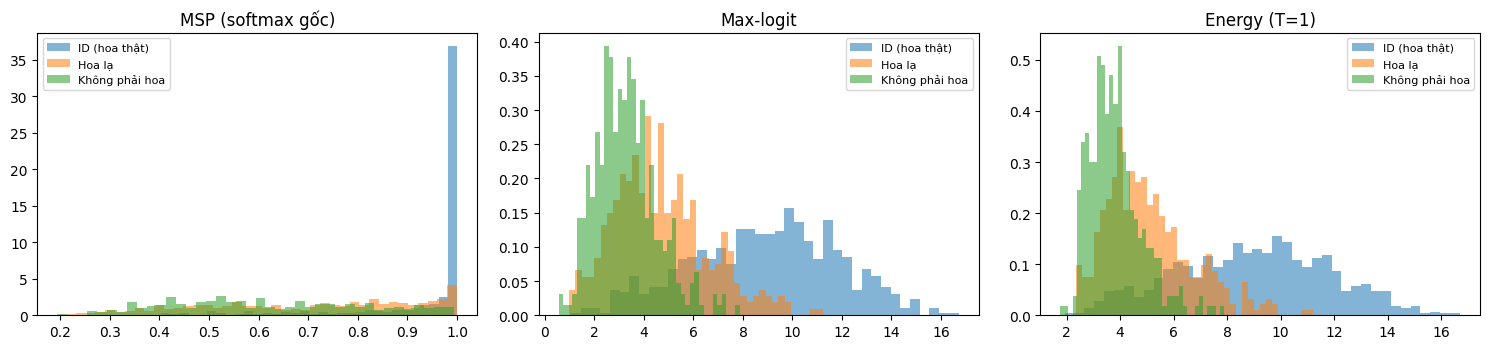

In [14]:
# ===== CELL 5: BASELINE OOD TRÊN VAL (MSP / MAX-LOGIT / ENERGY T=1) =====
from sklearn.metrics import roc_auc_score
from scipy.special import softmax, logsumexp

# 1. Nạp lại từ cache (không phụ thuộc biến trong bộ nhớ)
def load_ood_table():
    df = pd.read_csv(f'{OOD_DIR}/ood_split.csv')
    c = np.load(OOD_CACHE)
    idx = {p: i for i, p in enumerate(c['paths'])}
    pos = [idx[p] for p in df['path']]
    return df, c['logits'][pos], c['feats'][pos]

ood_df, ood_lg_all, ood_ft_all = load_ood_table()
val_mask = (ood_df['split'] == 'val').values
ood_val_df, ood_val_lg = ood_df[val_mask].reset_index(drop=True), ood_lg_all[val_mask]
id_val_lg = np.load(f'{OOD_OUT_DIR}/id_val.npz')['logits']
print(f'ID val: {len(id_val_lg)} | OOD val: {len(ood_val_lg)}')

# 2. Các điểm số (điểm CAO = giống ID)
def score_msp(lg):            return softmax(lg, axis=1).max(axis=1)
def score_maxlogit(lg):       return lg.max(axis=1)
def score_energy(lg, T=1.0):  return T * logsumexp(lg / T, axis=1)      # = -Energy
SCORES = {'MSP (softmax gốc)': score_msp, 'Max-logit': score_maxlogit, 'Energy (T=1)': score_energy}

# 3. Chỉ số: AUROC và FPR khi giữ 95% ảnh ID thật
def evaluate(s_id, s_ood, tpr=0.95):
    y = np.r_[np.ones(len(s_id)), np.zeros(len(s_ood))]
    auroc = roc_auc_score(y, np.r_[s_id, s_ood])
    thr = np.percentile(s_id, 100 * (1 - tpr))      # 95% ảnh ID có điểm >= thr
    fpr = (s_ood >= thr).mean()
    return auroc, fpr

types = ['near_flower', 'far_texture', 'far_animal', 'far_own', 'bg_crop']
rows = []
for name, fn in SCORES.items():
    s_id = fn(id_val_lg)
    for t in types:
        m = (ood_val_df['ood_type'] == t).values
        a, f = evaluate(s_id, fn(ood_val_lg[m]))
        rows.append({'method': name, 'ood_type': t, 'AUROC': a, 'FPR@95': f})
res = pd.DataFrame(rows)

auroc_tab = res.pivot(index='method', columns='ood_type', values='AUROC')[types]
fpr_tab   = res.pivot(index='method', columns='ood_type', values='FPR@95')[types]
auroc_tab['macro'] = auroc_tab.mean(axis=1); fpr_tab['macro'] = fpr_tab.mean(axis=1)
print('\nAUROC (càng cao càng tốt):');  print(auroc_tab.round(3))
print('\nFPR@95%TPR (càng thấp càng tốt):'); print(fpr_tab.round(3))

# 4. Histogram: ID vs hoa lạ vs không phải hoa
far_mask = ood_val_df['ood_type'].isin(['far_texture', 'far_animal', 'far_own', 'bg_crop']).values
near_mask = (ood_val_df['ood_type'] == 'near_flower').values
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (name, fn) in zip(axes, SCORES.items()):
    ax.hist(fn(id_val_lg), bins=40, alpha=.55, density=True, label='ID (hoa thật)')
    ax.hist(fn(ood_val_lg[near_mask]), bins=40, alpha=.55, density=True, label='Hoa lạ')
    ax.hist(fn(ood_val_lg[far_mask]), bins=40, alpha=.55, density=True, label='Không phải hoa')
    ax.set_title(name); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

T_cal = 1.166
                 NLL     ECE     Acc
val  (T=1)    0.2557  0.0194  0.9281
val  (T_cal)  0.2512  0.0237  0.9281
test (T=1)    0.1998  0.0174  0.9309
test (T_cal)  0.2028  0.0207  0.9309


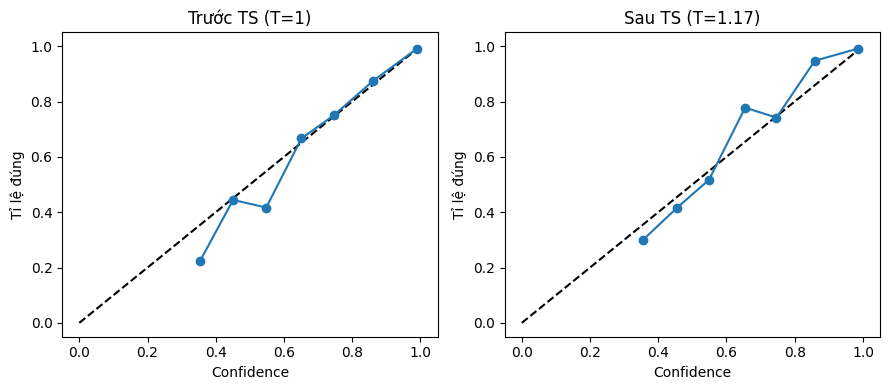


AUROC:
type       near_flower  far_texture  far_animal  far_own  bg_crop
method                                                           
MSP (T=1)        0.875        0.929       0.933    0.905    0.906
MSP + TS         0.876        0.932       0.936    0.909    0.911
FPR@95:
type       near_flower  far_texture  far_animal  far_own  bg_crop
method                                                           
MSP (T=1)        0.663        0.471       0.500    0.567    0.637
MSP + TS         0.656        0.426       0.458    0.567    0.582


In [15]:
# ===== CELL 6: TEMPERATURE SCALING (T_cal) =====
from scipy.optimize import minimize_scalar

d_val  = np.load(f'{OOD_OUT_DIR}/id_val.npz');  d_test = np.load(f'{OOD_OUT_DIR}/id_test.npz')
lg_v, y_v = d_val['logits'],  d_val['labels']
lg_t, y_t = d_test['logits'], d_test['labels']

def nll(lg, y, T):
    lp = lg / T - logsumexp(lg / T, axis=1, keepdims=True)
    return -lp[np.arange(len(y)), y].mean()

def ece(lg, y, T=1.0, bins=15):
    p = softmax(lg / T, axis=1); conf = p.max(1); correct = (p.argmax(1) == y)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

# 1. Fit T trên val ID (1 tham số, tối thiểu NLL)
T_cal = minimize_scalar(lambda T: nll(lg_v, y_v, T), bounds=(0.05, 10), method='bounded').x
print(f'T_cal = {T_cal:.3f}')
print(f'{"":12s}{"NLL":>8s}{"ECE":>8s}{"Acc":>8s}')
for nm, lg, y in [('val  (T=1)', lg_v, y_v), ('val  (T_cal)', lg_v / T_cal, y_v),
                  ('test (T=1)', lg_t, y_t), ('test (T_cal)', lg_t / T_cal, y_t)]:
    print(f'{nm:12s}{nll(lg, y, 1.0):8.4f}{ece(lg, y):8.4f}{(lg.argmax(1) == y).mean():8.4f}')

# 2. Reliability diagram trên TEST
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, T, ttl in zip(axes, [1.0, T_cal], ['Trước TS (T=1)', f'Sau TS (T={T_cal:.2f})']):
    p = softmax(lg_t / T, axis=1); conf = p.max(1); cor = (p.argmax(1) == y_t)
    edges = np.linspace(0, 1, 11); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(cor[m].mean())
    ax.plot([0, 1], [0, 1], 'k--'); ax.plot(xs, ys, 'o-')
    ax.set_title(ttl); ax.set_xlabel('Confidence'); ax.set_ylabel('Tỉ lệ đúng')
plt.tight_layout(); plt.show()

# 3. TS có giúp phát hiện OOD không? (đối chứng, kỳ vọng: gần như không)
rows = []
for nm, fn in [('MSP (T=1)', score_msp), ('MSP + TS', lambda lg: score_msp(lg / T_cal))]:
    s_id = fn(id_val_lg)
    for t in types:
        m = (ood_val_df['ood_type'] == t).values
        a, f = evaluate(s_id, fn(ood_val_lg[m])); rows.append({'method': nm, 'type': t, 'AUROC': a, 'FPR': f})
r = pd.DataFrame(rows)
print('\nAUROC:'); print(r.pivot(index='method', columns='type', values='AUROC')[types].round(3))
print('FPR@95:'); print(r.pivot(index='method', columns='type', values='FPR')[types].round(3))

      AUROC_macro  FPR_macro  AUROC_near  FPR_near  AUROC_bg  FPR_bg
T                                                                   
0.5         0.935      0.432       0.874     0.675     0.954   0.297
1.0         0.935      0.435       0.872     0.688     0.957   0.264
2.0         0.933      0.469       0.863     0.733     0.959   0.275
5.0         0.917      0.455       0.817     0.779     0.951   0.264
10.0        0.864      0.613       0.709     0.887     0.913   0.516
20.0        0.735      0.810       0.523     0.959     0.799   0.857

T tốt nhất = 1.0 (hơn T=1: +0.0000) -> chọn T_energy = 1.0


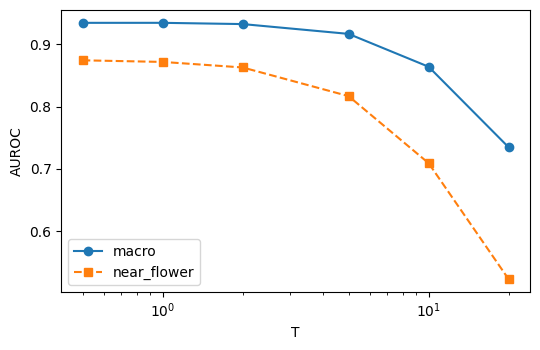

In [16]:
# ===== CELL 7: QUÉT T CHO ENERGY (T_energy) =====
T_GRID = [0.5, 1, 2, 5, 10, 20]
MIN_GAIN = 0.005                       # quy tắc chốt trước khi chạy

rows = []
for T in T_GRID:
    fn = lambda lg, T=T: score_energy(lg, T)
    s_id = fn(id_val_lg); aur, fpr = {}, {}
    for t in types:
        m = (ood_val_df['ood_type'] == t).values
        aur[t], fpr[t] = evaluate(s_id, fn(ood_val_lg[m]))
    rows.append({'T': T, 'AUROC_macro': np.mean(list(aur.values())), 'FPR_macro': np.mean(list(fpr.values())),
                 'AUROC_near': aur['near_flower'], 'FPR_near': fpr['near_flower'],
                 'AUROC_bg': aur['bg_crop'], 'FPR_bg': fpr['bg_crop']})
sweep = pd.DataFrame(rows).set_index('T')
print(sweep.round(3))

best_T = sweep['AUROC_macro'].idxmax()
gain = sweep.loc[best_T, 'AUROC_macro'] - sweep.loc[1, 'AUROC_macro']
T_energy = float(best_T) if gain >= MIN_GAIN else 1.0
print(f'\nT tốt nhất = {best_T} (hơn T=1: {gain:+.4f}) -> chọn T_energy = {T_energy}')

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(sweep.index, sweep['AUROC_macro'], 'o-', label='macro'); ax.plot(sweep.index, sweep['AUROC_near'], 's--', label='near_flower')
ax.set_xscale('log'); ax.set_xlabel('T'); ax.set_ylabel('AUROC'); ax.legend(); plt.tight_layout(); plt.show()

# Lưu tạm để các cell sau và backend dùng
import json
with open(f'{OOD_OUT_DIR}/ood_partial.json', 'w') as f:
    json.dump({'T_cal': float(T_cal), 'T_energy': T_energy}, f, indent=2)

In [17]:
# ===== CELL 8: MAHALANOBIS (MD) + RELATIVE MAHALANOBIS (RMD) =====
from sklearn.covariance import LedoitWolf

d_tr = np.load(f'{OOD_OUT_DIR}/id_train.npz')
F_tr, y_tr = d_tr['feats'].astype('float64'), d_tr['labels']
F_id_val   = np.load(f'{OOD_OUT_DIR}/id_val.npz')['feats'].astype('float64')
F_ood_val  = ood_ft_all[val_mask].astype('float64')

# 1. Tâm từng lớp + hiệp phương sai CHUNG; co rút Ledoit-Wolf vì 1024 chiều so với 3507 mẫu
means    = np.stack([F_tr[y_tr == k].mean(0) for k in range(NUM_CLASSES)])
P_tied   = LedoitWolf(assume_centered=True).fit(F_tr - means[y_tr]).precision_
mu0      = F_tr.mean(0)
P_glob   = LedoitWolf(assume_centered=True).fit(F_tr - mu0).precision_

def maha(F, mu, P):
    D = F - mu
    return ((D @ P) * D).sum(1)

def md_all(F):                                    # (N, 10): khoảng cách tới từng lớp
    return np.stack([maha(F, means[k], P_tied) for k in range(NUM_CLASSES)], axis=1)

def score_md(F):  return -md_all(F).min(axis=1)                                   # điểm cao = giống ID
def score_rmd(F): return -(md_all(F) - maha(F, mu0, P_glob)[:, None]).min(axis=1)

# 2. Kiểm tra: phân loại bằng tâm lớp gần nhất phải cho accuracy hợp lý (≈ 0.9)
acc_md = (md_all(F_id_val).argmin(1) == np.load(f'{OOD_OUT_DIR}/id_val.npz')['labels']).mean()
print(f'Sanity: accuracy theo tâm lớp gần nhất trên ID val = {acc_md:.3f}')

# 3. So sánh với các phương pháp logit trên cùng tập val
methods = {
    'MSP (softmax gốc)': (score_msp(id_val_lg),    lambda m: score_msp(ood_val_lg[m])),
    'Energy (T=1)'     : (score_energy(id_val_lg), lambda m: score_energy(ood_val_lg[m])),
    'Mahalanobis (MD)' : (score_md(F_id_val),      lambda m: score_md(F_ood_val[m])),
    'Relative MD (RMD)': (score_rmd(F_id_val),     lambda m: score_rmd(F_ood_val[m])),
}
rows = []
for name, (s_id, f_ood) in methods.items():
    for t in types:
        m = (ood_val_df['ood_type'] == t).values
        a, f = evaluate(s_id, f_ood(m)); rows.append({'method': name, 'ood_type': t, 'AUROC': a, 'FPR@95': f})
res8 = pd.DataFrame(rows)
order = list(methods.keys())
au = res8.pivot(index='method', columns='ood_type', values='AUROC')[types].loc[order]
fp = res8.pivot(index='method', columns='ood_type', values='FPR@95')[types].loc[order]
au['macro'] = au.mean(axis=1); fp['macro'] = fp.mean(axis=1)
print('\nAUROC:');  print(au.round(3))
print('\nFPR@95%TPR:'); print(fp.round(3))

Sanity: accuracy theo tâm lớp gần nhất trên ID val = 0.911

AUROC:
ood_type           near_flower  far_texture  far_animal  far_own  bg_crop  \
method                                                                      
MSP (softmax gốc)        0.875        0.929       0.933    0.905    0.906   
Energy (T=1)             0.872        0.958       0.948    0.939    0.957   
Mahalanobis (MD)         0.658        0.983       0.961    0.894    0.939   
Relative MD (RMD)        0.898        0.183       0.468    0.533    0.351   

ood_type           macro  
method                    
MSP (softmax gốc)  0.909  
Energy (T=1)       0.935  
Mahalanobis (MD)   0.887  
Relative MD (RMD)  0.486  

FPR@95%TPR:
ood_type           near_flower  far_texture  far_animal  far_own  bg_crop  \
method                                                                      
MSP (softmax gốc)        0.663        0.471       0.500    0.567    0.637   
Energy (T=1)             0.688        0.277       0.444    0.500

In [18]:
# ===== CELL 8b: KẾT HỢP ĐIỂM SỐ THEO QUY TẮC "LOẠI NẾU MỘT ĐIỂM THẤP" =====
def make_q(s_ref):
    ref = np.sort(s_ref)
    return lambda s: np.searchsorted(ref, s, side='right') / len(ref)

raw = {   # (điểm ID val, điểm OOD val) - điểm cao = giống ID
    'E'  : (score_energy(id_val_lg), score_energy(ood_val_lg)),
    'MD' : (score_md(F_id_val),      score_md(F_ood_val)),
    'RMD': (score_rmd(F_id_val),     score_rmd(F_ood_val)),
}
Q    = {k: make_q(v[0]) for k, v in raw.items()}
qid  = {k: Q[k](raw[k][0]) for k in raw}
qood = {k: Q[k](raw[k][1]) for k in raw}

combos = {
    'Energy'            : ['E'],
    'MD'                : ['MD'],
    'RMD'               : ['RMD'],
    'Energy ∨ RMD'      : ['E', 'RMD'],
    'MD ∨ RMD'          : ['MD', 'RMD'],
    'Energy ∨ MD ∨ RMD' : ['E', 'MD', 'RMD'],
}
rows = []
for name, keys in combos.items():
    s_id = np.min([qid[k] for k in keys], axis=0)
    for t in types:
        m = (ood_val_df['ood_type'] == t).values
        s_ood = np.min([qood[k][m] for k in keys], axis=0)
        a, f = evaluate(s_id, s_ood)
        rows.append({'method': name, 'ood_type': t, 'AUROC': a, 'FPR@95': f})
res8b = pd.DataFrame(rows)
order = list(combos.keys())
au = res8b.pivot(index='method', columns='ood_type', values='AUROC')[types].loc[order]
fp = res8b.pivot(index='method', columns='ood_type', values='FPR@95')[types].loc[order]
au['macro'] = au.mean(axis=1); fp['macro'] = fp.mean(axis=1)
print('AUROC:');  print(au.round(3))
print('\nFPR@95%TPR:'); print(fp.round(3))

AUROC:
ood_type           near_flower  far_texture  far_animal  far_own  bg_crop  \
method                                                                      
Energy                   0.873        0.959       0.949    0.939    0.957   
MD                       0.659        0.983       0.961    0.894    0.940   
RMD                      0.899        0.183       0.468    0.534    0.352   
Energy ∨ RMD             0.898        0.934       0.918    0.917    0.933   
MD ∨ RMD                 0.867        0.969       0.928    0.873    0.922   
Energy ∨ MD ∨ RMD        0.877        0.980       0.950    0.916    0.967   

ood_type           macro  
method                    
Energy             0.935  
MD                 0.888  
RMD                0.487  
Energy ∨ RMD       0.920  
MD ∨ RMD           0.912  
Energy ∨ MD ∨ RMD  0.938  

FPR@95%TPR:
ood_type           near_flower  far_texture  far_animal  far_own  bg_crop  \
method                                                                

In [19]:
# ===== CELL 9: ĐÁNH GIÁ TRÊN TEST (NGƯỠNG CHỐT TỪ VAL) =====
# Đặt TRƯỚC khi chạy: mức FPR@95 chấp nhận được cho hoa lạ (cấp vùng). None nếu chưa đặt.
X_NEAR_FPR = None        # ví dụ 0.30; ghi rõ nguồn (giáo viên / nhóm tự đặt)

# 1. Dữ liệu test
d_te       = np.load(f'{OOD_OUT_DIR}/id_test.npz')
id_te_lg, id_te_ft, id_te_y = d_te['logits'], d_te['feats'].astype('float64'), d_te['labels']
te_mask    = (ood_df['split'] == 'test').values
ood_te_df  = ood_df[te_mask].reset_index(drop=True)
ood_te_lg  = ood_lg_all[te_mask]
ood_te_ft  = ood_ft_all[te_mask].astype('float64')
print(f'ID test: {len(id_te_lg)} | OOD test: {len(ood_te_lg)}')

# 2. Điểm test cho 3 tiêu chí, quy về phân vị theo ID VAL (Q đã fit ở Cell 8b)
te_raw = {'E':   (score_energy(id_te_lg), score_energy(ood_te_lg)),
          'MD':  (score_md(id_te_ft),     score_md(ood_te_ft)),
          'RMD': (score_rmd(id_te_ft),    score_rmd(ood_te_ft))}
q_te_id  = {k: Q[k](te_raw[k][0]) for k in te_raw}
q_te_ood = {k: Q[k](te_raw[k][1]) for k in te_raw}

# 3. Quy tắc chọn đã chốt trước: FPR macro thấp nhất trên val
chosen_name = fp['macro'].idxmin(); chosen_keys = combos[chosen_name]
print('Phương pháp được chọn (theo val):', chosen_name)

def run(keys):
    s_val = np.min([qid[k] for k in keys], axis=0)
    tau = np.percentile(s_val, 5)                          # giữ 95% ID val
    s_id  = np.min([q_te_id[k] for k in keys], axis=0)
    s_ood = np.min([q_te_ood[k] for k in keys], axis=0)
    return tau, s_id, s_ood

def table_row(name, keep_id, keep_ood):
    row = {'method': name, 'ID giữ lại': keep_id.mean()}
    for t in types:
        m = (ood_te_df['ood_type'] == t).values
        row[t] = keep_ood[m].mean()
    row['macro'] = np.mean([row[t] for t in types])
    return row

rows = []
# a) Hệ thống hiện tại: softmax >= 0.85 (không tinh chỉnh gì)
rows.append(table_row('MSP >= 0.85 (hiện tại)', score_msp(id_te_lg) >= 0.85, score_msp(ood_te_lg) >= 0.85))
# b) Baseline với ngưỡng 95% ID val
for nm, fn_id, fn_ood, ref in [('MSP (95% ID val)', score_msp(id_te_lg), score_msp(ood_te_lg), score_msp(id_val_lg))]:
    thr = np.percentile(ref, 5); rows.append(table_row(nm, fn_id >= thr, fn_ood >= thr))
for nm, keys in [('Energy', ['E']), ('MD', ['MD']), ('RMD', ['RMD']), (chosen_name + '  <- được chọn', chosen_keys)]:
    tau, s_id, s_ood = run(keys); rows.append(table_row(nm, s_id >= tau, s_ood >= tau))
res9 = pd.DataFrame(rows).set_index('method')
print('\nCột "ID giữ lại" càng cao càng tốt; các cột còn lại là FPR (ảnh lạ lọt qua) càng thấp càng tốt:')
print(res9.round(3))

# 4. Khoảng tin cậy bootstrap 95% cho phương pháp được chọn
tau, s_id, s_ood = run(chosen_keys)
rb = np.random.RandomState(SEED)
def ci(flags, n=2000):
    ms = [flags[rb.randint(0, len(flags), len(flags))].mean() for _ in range(n)]
    return np.percentile(ms, [2.5, 97.5])
print('\nKhoảng tin cậy 95% (phương pháp được chọn):')
lo, hi = ci(s_id >= tau); print(f'  ID giữ lại   : {(s_id >= tau).mean():.3f}  [{lo:.3f}, {hi:.3f}]')
for t in types:
    m = (ood_te_df['ood_type'] == t).values
    f = s_ood[m] >= tau; lo, hi = ci(f)
    print(f'  {t:12s} n={m.sum():3d} FPR {f.mean():.3f}  [{lo:.3f}, {hi:.3f}]')

# 5. Ảnh ID thật bị loại nhầm theo từng lớp (phát hiện lớp hiếm bị loại oan)
rej = pd.Series(s_id < tau).groupby(id_te_y).agg(['mean', 'size'])
rej.index = [CLASS_NAMES[CLASS_IDS[i]] for i in rej.index]
print('\nTỉ lệ ảnh hoa thật bị loại nhầm, theo lớp (test):'); print(rej.rename(columns={'mean': 'bị loại', 'size': 'n'}).round(3))

# 6. Lưu kết quả cho báo cáo
res9.to_csv(f'{OOD_OUT_DIR}/ood_test_results.csv')
if X_NEAR_FPR is not None:
    near = res9.loc[chosen_name + '  <- được chọn', 'near_flower']
    print(f'\nSo với X: near_flower FPR = {near:.3f} vs X = {X_NEAR_FPR} ->', 'ĐẠT' if near <= X_NEAR_FPR else 'CHƯA ĐẠT')

ID test: 752 | OOD test: 405
Phương pháp được chọn (theo val): Energy ∨ MD ∨ RMD

Cột "ID giữ lại" càng cao càng tốt; các cột còn lại là FPR (ảnh lạ lọt qua) càng thấp càng tốt:
                                 ID giữ lại  near_flower  far_texture  \
method                                                                  
MSP >= 0.85 (hiện tại)                0.854        0.275        0.125   
MSP (95% ID val)                      0.952        0.614        0.425   
Energy                                0.968        0.712        0.225   
MD                                    0.957        0.847        0.162   
RMD                                   0.944        0.352        1.000   
Energy ∨ MD ∨ RMD  <- được chọn       0.961        0.508        0.100   

                                 far_animal  far_own  bg_crop  macro  
method                                                                
MSP >= 0.85 (hiện tại)                0.051    0.200    0.171  0.165  
MSP (95% ID val)        

In [20]:
# ===== CELL 11a: HÀM MÔ PHỎNG PIPELINE (COPY TỪ backend/predict.py) =====
IMG_SIZE_T = (224, 224)
IOU_MERGE_THRESHOLD = 0.3
CONTAINMENT_THRESHOLD = 0.75

def generate_windows(width, height):
    windows = [(0, 0, width, height),
               (0, 0, width // 2, height), (width // 2, 0, width, height),
               (0, 0, width, height // 2), (0, height // 2, width, height)]
    for i in range(3):
        windows.append((i * width // 3, 0, (i + 1) * width // 3, height))
    for i in range(2):
        y1, y2 = i * height // 2, (i + 1) * height // 2
        windows.append((0, y1, width // 2, y2)); windows.append((width // 2, y1, width, y2))
    step_x, step_y, win_w, win_h = width // 4, height // 4, width // 2, height // 2
    for gy in range(3):
        for gx in range(3):
            x1, y1 = gx * step_x, gy * step_y
            x2, y2 = min(x1 + win_w, width), min(y1 + win_h, height)
            if x2 - x1 > 20 and y2 - y1 > 20: windows.append((x1, y1, x2, y2))
    return windows

def crop_to_square(img, box):
    region = img.crop(box); w, h = region.size; s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return region.crop((left, top, left + s, top + s)).resize(IMG_SIZE_T)   # giữ NGUYÊN như backend

def iou(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

def containment_ratio(inner, outer):
    x1, y1, x2, y2 = max(inner[0], outer[0]), max(inner[1], outer[1]), min(inner[2], outer[2]), min(inner[3], outer[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area = (inner[2] - inner[0]) * (inner[3] - inner[1])
    return inter / area if area > 0 else 0

# Một model xuất đồng thời logit và feature (1 lần chạy)
lf_model = keras.Model(model.input, [logit_model.output, feat_model.output])

def pipeline_scores(img_paths, imgs_per_chunk=8):
    """Với mỗi ảnh: 21 cửa sổ -> (box, lớp argmax, MSP, điểm OOD kết hợp s = min phân vị của E/MD/RMD)."""
    out = []
    for i in range(0, len(img_paths), imgs_per_chunk):
        metas, crops = [], []
        for p in img_paths[i:i + imgs_per_chunk]:
            img = Image.open(p).convert('RGB'); wins = generate_windows(*img.size)
            metas.append((p, wins))
            crops += [np.array(crop_to_square(img, b), dtype=np.float32) for b in wins]
        lg, ft = lf_model.predict(np.stack(crops), batch_size=64, verbose=0)
        ft = ft.astype('float64')
        s = np.min([Q['E'](score_energy(lg)), Q['MD'](score_md(ft)), Q['RMD'](score_rmd(ft))], axis=0)
        msp, cls = softmax(lg, axis=1).max(1), lg.argmax(1); k = 0
        for p, wins in metas:
            n = len(wins)
            out.append({'path': p, 'boxes': wins, 'cls': cls[k:k + n], 'msp': msp[k:k + n], 's': s[k:k + n]}); k += n
        print(f'  {min(i + imgs_per_chunk, len(img_paths))}/{len(img_paths)}', end='\r')
    print(); return out

def detect_sim(rec, theta, gate):
    """Giống detect_flowers(): chỉ thay 'MSP >= 0.85' bằng 'điểm OOD >= theta VÀ MSP >= gate'."""
    cands = [(int(c), float(m), b) for b, c, m, s in zip(rec['boxes'], rec['cls'], rec['msp'], rec['s'])
             if s >= theta and m >= gate]
    cands.sort(key=lambda t: t[1], reverse=True)
    kept = []
    for c, m, b in cands:
        if any(kc != c and containment_ratio(b, kb) >= CONTAINMENT_THRESHOLD for kc, _, kb in kept): continue
        if any(kc == c and iou(b, kb) >= IOU_MERGE_THRESHOLD for kc, _, kb in kept): continue
        kept.append((c, m, b))
    return {c for c, _, _ in kept}

In [23]:

# ===== CELL 11b: ĐIỂM CỬA SỔ CHO TOÀN BỘ ẢNH VAL (CHẠY 1 LẦN, CÓ CACHE) =====
import pickle

id_val_rows   = split_df[split_df['split'] == 'val']
id_val_paths  = id_val_rows['path'].tolist(); id_val_y = id_val_rows['label'].values
ood_val_paths = ood_val_df['path'].tolist()
WIN_CACHE = f'{OOD_OUT_DIR}/win_val.pkl'

if os.path.exists(WIN_CACHE):
    id_recs, ood_recs = pickle.load(open(WIN_CACHE, 'rb'))
else:
    print('ID val:');  id_recs  = pipeline_scores(id_val_paths)
    print('OOD val:'); ood_recs = pipeline_scores(ood_val_paths)
    pickle.dump((id_recs, ood_recs), open(WIN_CACHE, 'wb'))
print(len(id_recs), 'ảnh ID |', len(ood_recs), 'ảnh OOD')

751 ảnh ID | 764 ảnh OOD


In [24]:
# ===== CELL 11b-fix: LƯU CACHE (không tính lại) =====
import pickle

assert 'id_recs' in globals() and 'ood_recs' in globals(), \
    'Biến đã mất (runtime khởi động lại?) -> chạy lại Cell 11b sau khi thêm import pickle'
assert len(id_recs) == 751 and len(ood_recs) == 764, (len(id_recs), len(ood_recs))

with open(WIN_CACHE, 'wb') as f:
    pickle.dump((id_recs, ood_recs), f)
print('Đã lưu:', WIN_CACHE, '|', round(os.path.getsize(WIN_CACHE) / 1e6, 1), 'MB')

# Kiểm tra đọc lại được
with open(WIN_CACHE, 'rb') as f:
    a, b = pickle.load(f)
print('Đọc lại OK:', len(a), 'ảnh ID |', len(b), 'ảnh OOD')

Đã lưu: /content/drive/MyDrive/flower-multilabel-project/models/ood/win_val.pkl | 1.3 MB
Đọc lại OK: 751 ảnh ID | 764 ảnh OOD


In [25]:
# ===== CELL 11c: QUÉT NGƯỠNG CẤP ẢNH (VAL) =====
RET_LEVELS = [0.95, 0.90, 0.85, 0.80, 0.70, 0.60, 0.50]   # mức giữ ID cấp VÙNG; thấp = chặt hơn
GATES      = [0.0, 0.85]                                   # cổng softmax kèm theo
ID_MIN     = 0.95                                          # ràng buộc ID cấp ảnh (đặt trước khi chạy)

s_val_region = np.min([qid[k] for k in ['E', 'MD', 'RMD']], axis=0)       # từ Cell 8b
theta_of = {r: np.percentile(s_val_region, 100 * (1 - r)) for r in RET_LEVELS}

# Kiểm tra resample: cửa sổ toàn ảnh (cửa sổ 0) của ID val còn lại bao nhiêu ở r=0.95? (kỳ vọng ≈ 0.95)
full_s = np.array([r_['s'][0] for r_ in id_recs])
print(f'Kiểm tra: ID val (cửa sổ toàn ảnh) qua ngưỡng r=0.95: {(full_s >= theta_of[0.95]).mean():.3f}')

def eval_cfg(theta, gate):
    sets_id = [detect_sim(r_, theta, gate) for r_ in id_recs]
    row = {'ID_đúng':   np.mean([y in s for s, y in zip(sets_id, id_val_y)]),
           'ID_chính_xác': np.mean([s == {y} for s, y in zip(sets_id, id_val_y)]),
           'ID_nhãn_thừa': np.mean([len(s - {y}) > 0 for s, y in zip(sets_id, id_val_y)])}
    hit = np.array([len(detect_sim(r_, theta, gate)) > 0 for r_ in ood_recs])
    for t in types: row[t] = hit[(ood_val_df['ood_type'] == t).values].mean()
    row['far_TB'] = np.mean([row[t] for t in ['far_texture', 'far_animal', 'far_own', 'bg_crop']])
    return row

rows, names = [eval_cfg(-1.0, 0.85)], ['HIỆN TẠI (MSP>=0.85)']
for g in GATES:
    for r in RET_LEVELS:
        rows.append(eval_cfg(theta_of[r], g)); names.append(f'OOD r={r:.2f} | MSP>={g}')
sweep11 = pd.DataFrame(rows, index=names)
print(sweep11.round(3).to_string())

ok = sweep11.iloc[1:][sweep11.iloc[1:]['ID_đúng'] >= ID_MIN].sort_values('near_flower')
print(f'\nCấu hình thỏa ID_đúng >= {ID_MIN}, xếp theo near_flower tăng dần:')
print(ok[['ID_đúng', 'ID_nhãn_thừa', 'near_flower', 'far_TB']].round(3).head(5).to_string() if len(ok) else '(không có cấu hình nào thỏa)')

Kiểm tra: ID val (cửa sổ toàn ảnh) qua ngưỡng r=0.95: 0.951
                        ID_đúng  ID_chính_xác  ID_nhãn_thừa  near_flower  far_texture  far_animal  far_own  bg_crop  far_TB
HIỆN TẠI (MSP>=0.85)      0.947         0.860         0.125        0.858        0.477       0.722    0.600    0.758   0.639
OOD r=0.95 | MSP>=0.0     0.972         0.742         0.257        0.990        0.368       0.931    0.933    0.956   0.797
OOD r=0.90 | MSP>=0.0     0.961         0.780         0.214        0.849        0.174       0.653    0.633    0.593   0.513
OOD r=0.85 | MSP>=0.0     0.943         0.810         0.172        0.704        0.103       0.458    0.367    0.352   0.320
OOD r=0.80 | MSP>=0.0     0.925         0.823         0.141        0.589        0.039       0.153    0.233    0.220   0.161
OOD r=0.70 | MSP>=0.0     0.889         0.846         0.064        0.361        0.006       0.042    0.033    0.033   0.029
OOD r=0.60 | MSP>=0.0     0.828         0.811         0.029        0.233

In [26]:
import sys
sys.path.insert(0, f'{ROOT}/backend')
try:
    import predict as bp
    rec_of = {r_['path']: r_ for r_ in id_recs + ood_recs}
    sample = id_val_paths[:15] + ood_val_df[ood_val_df['ood_type'] == 'near_flower']['path'].tolist()[:15]
    diff = 0
    for p in sample:
        det, _, _ = bp.detect_flowers(open(p, 'rb').read())
        real = {d['id'] for d in det}
        sim  = {CLASS_IDS[c] for c in detect_sim(rec_of[p], -1.0, 0.85)}
        if real != sim: diff += 1; print('Khác:', os.path.basename(p), real, sim)
    print(f'Mô phỏng khớp backend: {len(sample) - diff}/{len(sample)}')
except Exception as e:
    print('Bỏ qua kiểm tra backend:', repr(e)[:200])

[model_loader] Đã nạp model đơn nhãn từ: /content/drive/MyDrive/flower-multilabel-project/models/final/flower_singlelabel_model.keras
Mô phỏng khớp backend: 30/30


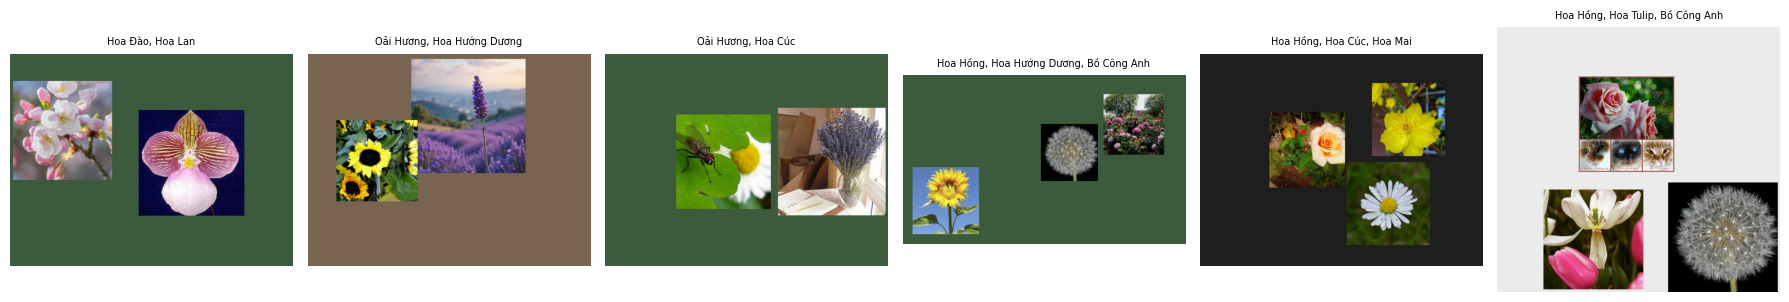

  150/150
                        2hoa_đủ_nhãn  2hoa_nhãn_thừa  3hoa_đủ_nhãn  3hoa_nhãn_thừa
HIỆN TẠI (MSP>=0.85)           0.760           0.080         0.360           0.080
OOD r=0.95 | MSP>=0.0          0.827           0.173         0.547           0.333
OOD r=0.90 | MSP>=0.0          0.747           0.107         0.387           0.227
OOD r=0.85 | MSP>=0.0          0.680           0.093         0.307           0.133
OOD r=0.80 | MSP>=0.0          0.627           0.067         0.267           0.093
OOD r=0.70 | MSP>=0.0          0.520           0.013         0.093           0.040
OOD r=0.60 | MSP>=0.0          0.400           0.000         0.067           0.027
OOD r=0.50 | MSP>=0.0          0.320           0.000         0.027           0.013
OOD r=0.95 | MSP>=0.85         0.720           0.040         0.307           0.080
OOD r=0.90 | MSP>=0.85         0.680           0.040         0.227           0.067
OOD r=0.85 | MSP>=0.85         0.613           0.027         0.200           

In [27]:
# ===== CELL 11e: ẢNH NHIỀU HOA (2-3 LOÀI) TỪ ẢNH VAL =====
MULTI_DIR = '/content/multi_val'; os.makedirs(MULTI_DIR, exist_ok=True)
N_EACH = 75                                               # 75 ảnh 2 hoa + 75 ảnh 3 hoa
rng_m = np.random.RandomState(SEED + 1)
by_class = {k: id_val_rows[id_val_rows['label'] == k]['path'].tolist() for k in range(NUM_CLASSES)}
BGS = [(235, 235, 235), (60, 90, 60), (120, 100, 80), (200, 215, 230), (30, 30, 30)]

def sq(img, s):
    w, h = img.size; m = min(w, h); l, t = (w - m) // 2, (h - m) // 2
    return img.crop((l, t, l + m, t + m)).resize((s, s), Image.BILINEAR)

def make_multi(k, idx):
    W, H = int(rng_m.choice([640, 720, 800])), int(rng_m.choice([480, 540, 600]))
    canvas = Image.new('RGB', (W, H), BGS[rng_m.randint(len(BGS))])
    classes_ = rng_m.choice(NUM_CLASSES, k, replace=False); boxes = []
    frac = 0.55 if k == 2 else 0.42
    for c in classes_:
        s = int(rng_m.uniform(0.8, 1.0) * frac * min(W, H))
        for _ in range(400):                              # tìm chỗ không chồng lấp
            x, y = rng_m.randint(0, W - s + 1), rng_m.randint(0, H - s + 1)
            if all(x + s <= bx or bx + bs <= x or y + s <= by or by + bs <= y for bx, by, bs in boxes): break
        else: s = int(s * 0.7); x, y = rng_m.randint(0, W - s + 1), rng_m.randint(0, H - s + 1)
        canvas.paste(sq(Image.open(rng_m.choice(by_class[c])).convert('RGB'), s), (x, y)); boxes.append((x, y, s))
    path = f'{MULTI_DIR}/m{k}_{idx:03d}.jpg'; canvas.save(path, quality=95)
    return path, set(int(c) for c in classes_), k

multi = [make_multi(k, i) for k in (2, 3) for i in range(N_EACH)]
multi_paths = [m[0] for m in multi]; multi_truth = [m[1] for m in multi]; multi_k = np.array([m[2] for m in multi])

# Xem thử 6 ảnh để kiểm tra bằng mắt
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, i in zip(axes, [0, 1, 2, N_EACH, N_EACH + 1, N_EACH + 2]):
    ax.imshow(Image.open(multi_paths[i])); ax.axis('off')
    ax.set_title(', '.join(CLASS_NAMES[CLASS_IDS[c]] for c in multi_truth[i]), fontsize=7)
plt.tight_layout(); plt.show()

multi_recs = pipeline_scores(multi_paths)

def eval_multi(theta, gate):
    sets = [detect_sim(r_, theta, gate) for r_ in multi_recs]
    row = {}
    for k in (2, 3):
        m = multi_k == k
        row[f'{k}hoa_đủ_nhãn'] = np.mean([truth <= s for s, truth, mm in zip(sets, multi_truth, m) if mm])
        row[f'{k}hoa_nhãn_thừa'] = np.mean([len(s - truth) > 0 for s, truth, mm in zip(sets, multi_truth, m) if mm])
    return row

mrows, mnames = [eval_multi(-1.0, 0.85)], ['HIỆN TẠI (MSP>=0.85)']
for g in GATES:
    for r in RET_LEVELS:
        mrows.append(eval_multi(theta_of[r], g)); mnames.append(f'OOD r={r:.2f} | MSP>={g}')
print(pd.DataFrame(mrows, index=mnames).round(3).to_string())

In [28]:
# ===== CELL 11f: NGƯỠNG THEO LOẠI CỬA SỔ + BẢNG TỔNG HỢP =====
assert all(len(r_['boxes']) == 21 for r_ in id_recs + ood_recs + multi_recs), 'Số cửa sổ không phải 21'
N_WIN = 21

def theta_per_window(r, gate=0.85):
    """Mỗi cửa sổ w: ngưỡng giữ r% các cửa sổ ID ĐÚNG (đoán đúng lớp, softmax >= gate) ở vị trí w."""
    vec = np.empty(N_WIN)
    for w in range(N_WIN):
        vals = [rec['s'][w] for rec, y in zip(id_recs, id_val_y) if rec['cls'][w] == y and rec['msp'][w] >= gate]
        vec[w] = np.percentile(vals, 100 * (1 - r)) if len(vals) >= 30 else -np.inf
    return vec

def detect_sim_v(rec, theta, gate):
    th = np.full(N_WIN, theta) if np.ndim(theta) == 0 else theta
    cands = [(int(c), float(m), b) for w, (b, c, m, s) in enumerate(zip(rec['boxes'], rec['cls'], rec['msp'], rec['s']))
             if s >= th[w] and m >= gate]
    cands.sort(key=lambda t: t[1], reverse=True); kept = []
    for c, m, b in cands:
        if any(kc != c and containment_ratio(b, kb) >= CONTAINMENT_THRESHOLD for kc, _, kb in kept): continue
        if any(kc == c and iou(b, kb) >= IOU_MERGE_THRESHOLD for kc, _, kb in kept): continue
        kept.append((c, m, b))
    return {c for c, _, _ in kept}

def eval_all(theta, gate=0.85):
    row = {}
    sets = [detect_sim_v(r_, theta, gate) for r_ in id_recs]
    row['1hoa_đúng']  = np.mean([y in s for s, y in zip(sets, id_val_y)])
    row['1hoa_thừa']  = np.mean([len(s - {y}) > 0 for s, y in zip(sets, id_val_y)])
    hit = np.array([len(detect_sim_v(r_, theta, gate)) > 0 for r_ in ood_recs])
    row['near_flower'] = hit[(ood_val_df['ood_type'] == 'near_flower').values].mean()
    far = ood_val_df['ood_type'].isin(['far_texture', 'far_animal', 'far_own', 'bg_crop']).values
    row['far_TB'] = np.mean([hit[(ood_val_df['ood_type'] == t).values].mean()
                             for t in ['far_texture', 'far_animal', 'far_own', 'bg_crop']])
    msets = [detect_sim_v(r_, theta, gate) for r_ in multi_recs]
    for k in (2, 3):
        idx = np.where(multi_k == k)[0]
        row[f'{k}hoa_đủ'] = np.mean([multi_truth[i] <= msets[i] for i in idx])
        row[f'{k}hoa_thừa'] = np.mean([len(msets[i] - multi_truth[i]) > 0 for i in idx])
    return row

rows, names = [eval_all(-1.0)], ['HIỆN TẠI (MSP>=0.85)']
for r in (0.95, 0.90, 0.85):
    rows.append(eval_all(theta_of[r]));            names.append(f'ngưỡng CHUNG   r={r:.2f}')
for r in (0.95, 0.90, 0.85, 0.80):
    rows.append(eval_all(theta_per_window(r)));    names.append(f'ngưỡng THEO CỬA SỔ r={r:.2f}')
summary = pd.DataFrame(rows, index=names)
print(summary.round(3).to_string())
summary.to_csv(f'{OOD_OUT_DIR}/summary_val_image_level.csv')

                           1hoa_đúng  1hoa_thừa  near_flower  far_TB  2hoa_đủ  2hoa_thừa  3hoa_đủ  3hoa_thừa
HIỆN TẠI (MSP>=0.85)           0.947      0.125        0.858   0.639    0.760      0.080    0.360      0.080
ngưỡng CHUNG   r=0.95          0.941      0.112        0.772   0.392    0.720      0.040    0.307      0.080
ngưỡng CHUNG   r=0.90          0.932      0.103        0.690   0.279    0.680      0.040    0.227      0.067
ngưỡng CHUNG   r=0.85          0.923      0.089        0.606   0.206    0.613      0.027    0.200      0.080
ngưỡng THEO CỬA SỔ r=0.95      0.939      0.112        0.755   0.406    0.720      0.040    0.320      0.093
ngưỡng THEO CỬA SỔ r=0.90      0.929      0.097        0.659   0.271    0.667      0.040    0.213      0.067
ngưỡng THEO CỬA SỔ r=0.85      0.916      0.088        0.553   0.165    0.640      0.040    0.200      0.067
ngưỡng THEO CỬA SỔ r=0.80      0.897      0.073        0.466   0.108    0.547      0.013    0.200      0.067


In [29]:
# ===== CELL 12a: CHIA LẠI LỚP HOA LẠ CHO BƯỚC 2 =====
# Quy tắc: 30 lớp TEST giữ nguyên; 53 lớp VAL cũ -> tách theo LỚP thành TRAIN-reject và VAL-mới.
old = pd.read_csv(f'{OOD_DIR}/ood_flower_split.csv')
test_cls    = sorted(old[old.split == 'test']['ox_label'].unique())
val_cls_old = sorted(old[old.split == 'val']['ox_label'].unique())
print(f'Lớp test (giữ nguyên): {len(test_cls)} | lớp val cũ: {len(val_cls_old)}')

rng12 = np.random.RandomState(SEED + 12)
perm = rng12.permutation(val_cls_old).tolist()
N_VAL_NEW = 18
val_cls_new, train_cls = set(perm[:N_VAL_NEW]), set(perm[N_VAL_NEW:])
PER_CLASS = {'train': 40, 'val': 20}                       # lớp Oxford có từ 40 ảnh trở lên

rows = []
for lb in val_cls_old:
    role = 'val' if lb in val_cls_new else 'train'
    sub = ox_df[ox_df['ox_label'] == lb]
    sub = sub.sample(min(PER_CLASS[role], len(sub)), random_state=SEED)
    rows += [{'path': p, 'ox_label': lb, 'role': role} for p in sub['path']]
te = old[old.split == 'test']
rows += [{'path': p, 'ox_label': lb, 'role': 'test'} for p, lb in zip(te['path'], te['ox_label'])]
flw = pd.DataFrame(rows)

# Kiểm tra trùng với TOÀN BỘ ảnh ID (train+val+test của model đơn nhãn); ảnh test đã lọc từ Cell 2b
new = flw[flw['role'] != 'test']
h = dhash_many(new['path'].tolist())
dmin = np.array([POP[np.bitwise_xor(id_h, x)].sum(axis=1).min() for x in h])
drop = new.index[dmin <= 6]
print(f'Ảnh nghi trùng ID bị loại: {len(drop)}/{len(new)}')
flw = flw.drop(index=drop).reset_index(drop=True)

assert not (train_cls & val_cls_new) and not (set(test_cls) & (train_cls | val_cls_new)), 'Lớp bị lẫn giữa các vai trò'
flw.to_csv(f'{OOD_DIR}/ood_step2_flower.csv', index=False)
print(flw.groupby('role').agg(ảnh=('path', 'size'), lớp=('ox_label', 'nunique')))

Lớp test (giữ nguyên): 30 | lớp val cũ: 53
Ảnh nghi trùng ID bị loại: 31/1760
        ảnh  lớp
role            
test    236   30
train  1370   35
val     359   18


 ox_label  role  số ảnh bị loại
       12 train               5
       33 train               4
       11 train               2
       92 train               2
       25 train               2
       74 train               2
       38 train               2
        5 train               1
       21 train               1
       19 train               1


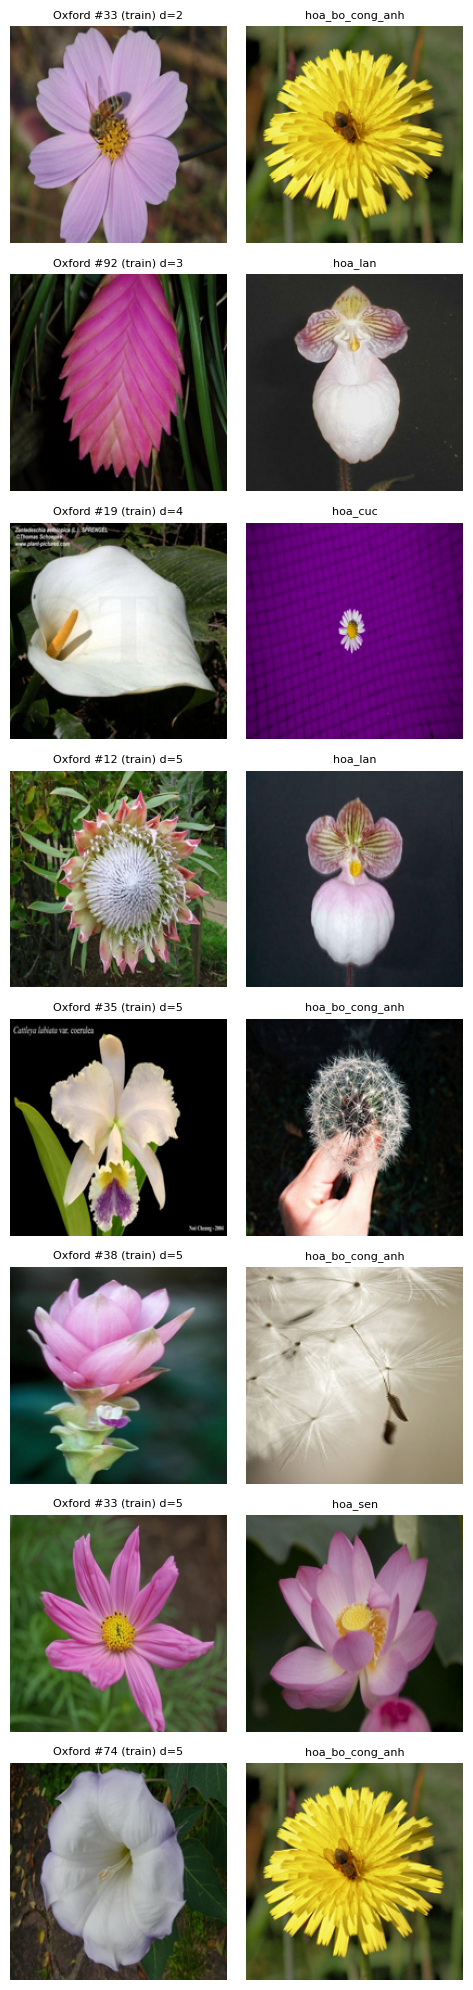

In [30]:
# ===== CELL 12a-check: LỚP NÀO BỊ LOẠI NHIỀU? =====
hit = new.copy(); hit['dist'] = dmin
hit = hit[hit['dist'] <= 6]
tab = (hit.groupby(['ox_label', 'role']).size().rename('số ảnh bị loại').reset_index()
          .sort_values('số ảnh bị loại', ascending=False))
print(tab.head(10).to_string(index=False))

top = hit.sort_values('dist').head(8)
fig, axes = plt.subplots(len(top), 2, figsize=(5, 2.5 * len(top)))
for r, (i, row) in enumerate(top.iterrows()):
    j = POP[np.bitwise_xor(id_h, dhash_bytes(row['path']))].sum(axis=1).argmin()
    axes[r, 0].imshow(Image.open(row['path']).convert('RGB').resize((200, 200)))
    axes[r, 0].set_title(f'Oxford #{row["ox_label"]} ({row["role"]}) d={row["dist"]}', fontsize=8)
    axes[r, 1].imshow(Image.open(split_df['path'].iloc[j]).convert('RGB').resize((200, 200)))
    axes[r, 1].set_title(split_df['class_id'].iloc[j], fontsize=8)
    for a in axes[r]: a.axis('off')
plt.tight_layout(); plt.show()

In [31]:
# ===== CELL 12b: DỮ LIỆU KHÔNG PHẢI HOA CHO BƯỚC 2 =====
rng12b = np.random.RandomState(SEED + 13)
old_nf = pd.read_csv(f'{OOD_DIR}/ood_nonflower_split.csv')

def full_dtd():
    d = collect([DTD(NF_SRC, split=s, download=True) for s in ['train', 'val', 'test']], 'dtd')
    return d[d['cls'] != 'flowery']
def full_pets():
    return collect([OxfordIIITPet(NF_SRC, split=s, download=True) for s in ['trainval', 'test']], 'pets')

def repartition_src(src, ood_type, n_train_per_cls, full_fn):
    full = full_fn()
    part = old_nf[old_nf['source'] == src]
    vcls = sorted(part[part.split == 'val']['cls'].unique())
    perm = rng12b.permutation(vcls).tolist()
    n_val_new = int(round(len(vcls) / 3))
    val_new, tr_cls = set(perm[:n_val_new]), set(perm[n_val_new:])
    rows = []
    pt = part[part.split == 'test']                                  # test: giữ nguyên
    rows += [(p, c, 'test') for p, c in zip(pt['path'], pt['cls'])]
    pv = part[(part.split == 'val') & part['cls'].isin(val_new)]      # val mới: dùng lại ảnh val cũ
    rows += [(p, c, 'val') for p, c in zip(pv['path'], pv['cls'])]
    ft = full[full['cls'].isin(tr_cls)]                               # train: ảnh MỚI của các lớp train
    ft = pd.concat([g.sample(min(len(g), n_train_per_cls), random_state=SEED) for _, g in ft.groupby('cls')])
    rows += [(p, c, 'train') for p, c in zip(ft['path'], ft['cls'])]
    out = pd.DataFrame(rows, columns=['path', 'cls', 'role']); out['ood_type'] = ood_type; out['source'] = src
    assert not (set(out[out.role == 'train']['cls']) & set(out[out.role != 'train']['cls'])), 'Lớp bị lẫn'
    print(f'{src}: lớp train {len(tr_cls)} | lớp val mới {len(val_new)} | lớp test {pt["cls"].nunique()}')
    return out

parts2 = [repartition_src('dtd',  'far_texture', 30, full_dtd),
          repartition_src('pets', 'far_animal',  15, full_pets)]

# Ảnh riêng + vùng nền cũ: giữ nguyên vai trò val/test
keep_old = old_nf[old_nf['ood_type'].isin(['far_own', 'bg_crop'])].rename(columns={'split': 'role'})
parts2.append(keep_old[['path', 'cls', 'role', 'ood_type', 'source']])

# Ảnh nền thu thập thêm cho TRAIN (nếu có)
TRAIN_NF = f'{OOD_DIR}/train_nonflower'
if os.path.isdir(TRAIN_NF):
    fs = sorted(f'{TRAIN_NF}/{f}' for f in os.listdir(TRAIN_NF) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
    tn = pd.DataFrame({'path': fs}); tn['cls'] = tn['path'].map(
        lambda p: re.sub(r'_?\d+$', '', os.path.splitext(os.path.basename(p))[0]).lower())
    tn['role'] = 'train'; tn['ood_type'] = 'far_own'; tn['source'] = 'own_train'
    parts2.append(tn); print('Ảnh nền train thêm:', len(tn), '| nhóm:', tn['cls'].nunique())
else:
    print('CHƯA có', TRAIN_NF, '-> bỏ qua (chỉ số bg_crop/far_own sẽ yếu hơn, ghi vào hạn chế)')

nf2 = pd.concat(parts2, ignore_index=True)
nf2.to_csv(f'{OOD_DIR}/ood_step2_nonflower.csv', index=False)

# Gộp với hoa lạ thành một bảng duy nhất cho Bước 2
fl2 = pd.read_csv(f'{OOD_DIR}/ood_step2_flower.csv')
fl2['ood_type'] = 'near_flower'; fl2['source'] = 'oxford'; fl2['cls'] = fl2['ox_label'].astype(str)
cols = ['path', 'cls', 'source', 'ood_type', 'role']
allp = pd.concat([fl2[cols], nf2[cols]], ignore_index=True)
assert allp['path'].is_unique, 'Trùng đường dẫn giữa các nguồn'
allp.to_csv(f'{OOD_DIR}/ood_step2_all.csv', index=False)
print(allp.groupby(['role', 'ood_type']).size().unstack(fill_value=0))

dtd: lớp train 21 | lớp val mới 10 | lớp test 16
pets: lớp train 16 | lớp val mới 8 | lớp test 13
CHƯA có /content/drive/MyDrive/flower-multilabel-project/data/ood/train_nonflower -> bỏ qua (chỉ số bg_crop/far_own sẽ yếu hơn, ghi vào hạn chế)
ood_type  bg_crop  far_animal  far_own  far_texture  near_flower
role                                                            
test           35          39       15           80          236
train           0         240        0          630         1370
val            91          24       30           50          359


In [33]:
# ===== CELL 12b-auto-1: ẢNH NỀN TỰ ĐỘNG TỪ PLACES365 =====
from torchvision.datasets import Places365
PL_ROOT = '/content/places365'
pl = Places365(PL_ROOT, split='val', small=True, download=True)    # ~0.5 GB, 100 ảnh/thể loại

KEEP_KW = ['forest', 'lawn', 'pasture', 'field_road', 'driveway', 'patio', 'porch', 'courtyard', 'alley',
           'sky', 'wall', 'brick', 'rock', 'cliff', 'canyon', 'desert', 'creek', 'pond', 'barn',
           'playground', 'parking', 'fence', 'bamboo', 'swamp']
DROP_KW = ['flower', 'garden', 'botanical', 'greenhouse', 'florist', 'orchard', 'wild', 'meadow', 'topiary']
cls_idx = [i for i, c in enumerate(pl.classes)
           if any(k in c for k in KEEP_KW) and not any(k in c for k in DROP_KW)]
print(len(cls_idx), 'thể loại được chọn:'); print(', '.join(pl.classes[i] for i in cls_idx))

imgs = pl.imgs
paths_all  = [x[0] if isinstance(x, (tuple, list)) else x for x in imgs]
labels_all = np.array([x[1] for x in imgs]) if isinstance(imgs[0], (tuple, list)) else np.array(pl.targets)

PER_CAT = 8
rng_p = np.random.RandomState(SEED + 15)
sel = []
for i in cls_idx:
    idxs = np.where(labels_all == i)[0]
    sel += rng_p.choice(idxs, min(PER_CAT, len(idxs)), replace=False).tolist()
bg = pd.DataFrame({'path': [paths_all[k] for k in sel], 'cat': [pl.classes[labels_all[k]] for k in sel]})
print('Số ảnh ứng viên:', len(bg))

# Tự kiểm tra: model hiện tại có thấy "hoa" ở cửa sổ nào không?
def flower_check(paths, chunk=16):
    mx, cl = [], []
    for i in range(0, len(paths), chunk):
        crops, spans = [], []
        for p in paths[i:i + chunk]:
            img = Image.open(p).convert('RGB'); wins = generate_windows(*img.size)
            crops += [np.array(crop_to_square(img, b), dtype=np.float32) for b in wins]; spans.append(len(wins))
        lg, _ = lf_model.predict(np.stack(crops), batch_size=64, verbose=0)
        pr = softmax(lg, axis=1); k = 0
        for n in spans:
            seg = pr[k:k + n]; best = seg.max(1); j = best.argmax()
            mx.append(float(best[j])); cl.append(int(seg[j].argmax())); k += n
    return np.array(mx), np.array(cl)

bg['max_msp'], bg['pred'] = flower_check(bg['path'].tolist())
flag = bg[bg['max_msp'] >= 0.85]
print(f'Model không thấy hoa (tự nhận): {len(bg) - len(flag)} | bị nghi, cần bạn xem: {len(flag)}')

# Contact sheet CHỈ cho ảnh bị nghi
cols = 8; rows_n = int(np.ceil(max(len(flag), 1) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 2.0, rows_n * 2.3))
for ax in np.atleast_1d(axes).ravel(): ax.axis('off')
for ax, (i, r) in zip(np.atleast_1d(axes).ravel(), flag.iterrows()):
    ax.imshow(Image.open(r['path']).convert('RGB'))
    ax.set_title(f'{i} | {CLASS_NAMES[CLASS_IDS[r["pred"]]][:9]}', fontsize=7)
plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [34]:
# ===== CELL 12b-auto-2: CHỐT ẢNH NỀN + GHÉP VÀO ood_step2_all.csv =====
REJECT_AUTO = [59, 152,197, 198, 199, 207, 210, 211, 214, 219, 236, 237]        # <- điền số thứ tự các ảnh CÓ HOA (từ bảng ở trên)
assert all(i in bg.index for i in REJECT_AUTO), 'Có số không thuộc bảng'
keep = bg[~bg.index.isin(REJECT_AUTO)]

AUTO_DIR = f'{OOD_DIR}/train_bg_auto'; os.makedirs(AUTO_DIR, exist_ok=True)
rows = []
for i, r in keep.iterrows():
    img = Image.open(r['path']).convert('RGB'); base = f'pl_{i:04d}'
    p0 = f'{AUTO_DIR}/{base}.jpg'; img.save(p0, quality=95); rows.append((p0, r['cat']))
    w, h = img.size; m = min(w, h)
    for k in range(3):                                           # 3 vùng cắt ngẫu nhiên / ảnh
        s = int(rng_p.choice([0.5, 0.65, 0.8]) * m)
        x, y = rng_p.randint(0, w - s + 1), rng_p.randint(0, h - s + 1)
        p = f'{AUTO_DIR}/{base}_c{k}.jpg'
        img.crop((x, y, x + s, y + s)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(p, quality=95)
        rows.append((p, r['cat']))
auto = pd.DataFrame(rows, columns=['path', 'cls'])
auto['role'] = 'train'; auto['ood_type'] = 'far_scene_public'; auto['source'] = 'places365'

S2 = pd.read_csv(f'{OOD_DIR}/ood_step2_all.csv')
S2 = S2[S2['source'] != 'places365']                               # chạy lại nhiều lần vẫn an toàn
S2 = pd.concat([S2, auto[S2.columns]], ignore_index=True)
assert S2['path'].is_unique
S2.to_csv(f'{OOD_DIR}/ood_step2_all.csv', index=False)

cache = f'{OOD_OUT_DIR}/step2_rej_train.npz'
if os.path.exists(cache): os.remove(cache); print('Đã xóa cache reject train cũ (sẽ tính lại ở 12c-1)')
print(f'Thêm {len(auto)} mẫu nền (từ {len(keep)} ảnh). Train hiện có:')
print(S2[S2['role'] == 'train'].groupby('ood_type').size())

Thêm 1072 mẫu nền (từ 268 ảnh). Train hiện có:
ood_type
far_animal           240
far_scene_public    1072
far_texture          630
near_flower         1370
dtype: int64


In [35]:
# ===== CELL 12c-1: TRÍCH ĐẶC TRƯNG CHO BƯỚC 2 (CACHE) =====
import pickle
S2 = pd.read_csv(f'{OOD_DIR}/ood_step2_all.csv')
S2_REJ = f'{OOD_OUT_DIR}/step2_rej_train.npz'
S2_WIN = f'{OOD_OUT_DIR}/step2_win_val.pkl'

# --- (1) reject TRAIN: đặc trưng nguyên ảnh ---
rej_tr = S2[S2['role'] == 'train'].reset_index(drop=True)
if os.path.exists(S2_REJ):
    c = np.load(S2_REJ, allow_pickle=True); assert list(c['paths']) == rej_tr['path'].tolist(), 'Cache lệch ood_step2_all.csv'
    rej_tr_lg, rej_tr_ft = c['logits'], c['feats']
else:
    rej_tr_lg, rej_tr_ft = extract(rej_tr['path'].tolist())
    np.savez_compressed(S2_REJ, paths=np.array(rej_tr['path']), logits=rej_tr_lg, feats=rej_tr_ft)
print('reject train:', rej_tr_ft.shape)

# --- (2) Kiểm tra loài chồng chéo: lớp Oxford nào bị model ID gán MẠNH và NHẤT QUÁN vào 1 lớp ID? ---
rej_tr['pred'] = rej_tr_lg.argmax(1); rej_tr['msp'] = softmax(rej_tr_lg, axis=1).max(1)
def summ(g):
    m = g['pred'].mode()[0]
    return pd.Series({'n': len(g), 'msp>=0.85': (g['msp'] >= 0.85).mean(),
                      'hay bị gán': CLASS_NAMES[CLASS_IDS[m]], 'tỉ lệ': (g['pred'] == m).mean()})
diag = rej_tr[rej_tr['ood_type'] == 'near_flower'].groupby('cls').apply(summ).sort_values('msp>=0.85', ascending=False)
print('\nLớp Oxford (train) bị gán mạnh vào lớp ID:'); print(diag.head(10).round(2).to_string())

# --- (3) đặc trưng + logit 21 cửa sổ cho ảnh VAL ---
def window_feats(paths, chunk=8):
    F, L, B = [], [], []
    for i in range(0, len(paths), chunk):
        crops = []
        for p in paths[i:i + chunk]:
            img = Image.open(p).convert('RGB'); wins = generate_windows(*img.size)
            assert len(wins) == 21, f'{p}: {len(wins)} cửa sổ'
            B.append(wins); crops += [np.array(crop_to_square(img, b), dtype=np.float32) for b in wins]
        lg, ft = lf_model.predict(np.stack(crops), batch_size=64, verbose=0)
        n = len(crops) // 21
        L.append(lg.reshape(n, 21, -1)); F.append(ft.reshape(n, 21, -1).astype('float16'))
        print(f'  {min(i + chunk, len(paths))}/{len(paths)}', end='\r')
    print(); return np.concatenate(F), np.concatenate(L), B

if os.path.exists(S2_WIN):
    WIN = pickle.load(open(S2_WIN, 'rb'))
else:
    rej_val = S2[S2['role'] == 'val'].reset_index(drop=True)
    WIN = {'rej_val': rej_val}
    for key, paths in [('id', id_val_paths), ('rej', rej_val['path'].tolist()), ('mul', multi_paths)]:
        print(key, len(paths)); WIN[key] = window_feats(paths)
    pickle.dump(WIN, open(S2_WIN, 'wb'))
print({k: v[0].shape for k, v in WIN.items() if k != 'rej_val'})

  3312/3312
reject train: (3312, 1024)

Lớp Oxford (train) bị gán mạnh vào lớp ID:
      n  msp>=0.85   hay bị gán  tỉ lệ
cls                                   
11   38       0.89  Bồ Công Anh   1.00
95   39       0.64     Hoa Hồng   0.67
30   39       0.62     Hoa Hồng   0.85
33   36       0.61      Hoa Cúc   0.92
10   40       0.57     Hoa Hồng   0.68
45   40       0.57      Hoa Mai   0.60
25   38       0.55     Hoa Hồng   0.82
38   38       0.50    Hoa Tulip   0.50
96   40       0.40     Hoa Hồng   0.68
26   39       0.38     Hoa Hồng   0.46


/tmp/ipykernel_393/3332013587.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  diag = rej_tr[rej_tr['ood_type'] == 'near_flower'].groupby('cls').apply(summ).sort_values('msp>=0.85', ascending=False)


{'id': (751, 21, 1024), 'rej': (554, 21, 1024), 'mul': (150, 21, 1024)}


In [36]:
# ===== CELL 12c-check: XEM LỚP NGHI CÙNG LOÀI + KIỂM TRA VAL/TEST =====
def show_cls(lbl, k=6):
    sub = rej_tr[(rej_tr['ood_type'] == 'near_flower') & (rej_tr['cls'].astype(str) == str(lbl))]
    pred = sub['pred'].mode()[0]
    idp = split_df[(split_df['split'] == 'train') & (split_df['label'] == pred)]['path'].sample(k, random_state=SEED).tolist()
    fig, axes = plt.subplots(2, k, figsize=(k * 2, 4.6))
    for a, p in zip(axes[0], sub['path'].sample(min(k, len(sub)), random_state=SEED)):
        a.imshow(Image.open(p).convert('RGB').resize((180, 180))); a.axis('off')
    for a, p in zip(axes[1], idp):
        a.imshow(Image.open(p).convert('RGB').resize((180, 180))); a.axis('off')
    axes[0, 0].set_title(f'Oxford #{lbl}', fontsize=9, loc='left')
    axes[1, 0].set_title(f'ID: {CLASS_NAMES[CLASS_IDS[pred]]}', fontsize=9, loc='left')
    plt.tight_layout(); plt.show()
for l in [11, 33, 25]: show_cls(l)

# Kiểm tra tương tự cho lớp VAL mới và lớp TEST (dùng logit nguyên ảnh)
rv = WIN['rej_val'].copy(); lg0 = WIN['rej'][1][:, 0, :]
rv['pred'] = lg0.argmax(1); rv['msp'] = softmax(lg0, axis=1).max(1)
rv = rv[rv['ood_type'] == 'near_flower']

fl2_ = pd.read_csv(f'{OOD_DIR}/ood_step2_flower.csv'); tst = fl2_[fl2_['role'] == 'test'].copy()
pos = {p: i for i, p in enumerate(ood_df['path'])}
lg_t = ood_lg_all[[pos[p] for p in tst['path']]]
tst['pred'] = lg_t.argmax(1); tst['msp'] = softmax(lg_t, axis=1).max(1); tst['cls'] = tst['ox_label'].astype(str)

for nm, df_ in [('VAL mới', rv), ('TEST', tst)]:
    d = df_.groupby('cls').apply(summ).sort_values('msp>=0.85', ascending=False)
    print(f'\n{nm}: lớp bị gán mạnh vào lớp ID'); print(d.head(6).round(2).to_string())

Output hidden; open in https://colab.research.google.com to view.

In [37]:
# ===== CELL 12c-noise: ẢNH 'BỒ CÔNG ANH' TRONG ID CÓ LẪN LOÀI #11? =====
from sklearn.preprocessing import normalize
d_tr_ = np.load(f'{OOD_OUT_DIR}/id_train.npz')
tr = split_df[split_df['split'] == 'train'].reset_index(drop=True)          # cùng thứ tự với id_train.npz
assert len(tr) == len(d_tr_['feats'])
CLS_DAN = ID2IDX['hoa_bo_cong_anh']
dan_idx = np.where(d_tr_['labels'] == CLS_DAN)[0]
F_dan = normalize(d_tr_['feats'][dan_idx].astype('float32'))
F_11  = normalize(rej_tr_ft[(rej_tr['cls'].astype(str) == '11').values].astype('float32'))
print(f'Ảnh Bồ Công Anh trong ID train: {len(F_dan)} | ảnh #11: {len(F_11)}')

S = F_dan @ np.vstack([F_dan, F_11]).T                  # độ giống cosine
ii = np.arange(len(F_dan)); S[ii, ii] = -1              # bỏ chính nó
nn = np.argsort(-S, axis=1)[:, :5]
frac11 = (nn >= len(F_dan)).mean(1)                     # tỉ lệ 5 láng giềng gần nhất là ảnh #11

res = pd.DataFrame({'path': tr.loc[dan_idx, 'path'].values, 'frac11': frac11}) \
        .sort_values('frac11', ascending=False).reset_index(drop=True)
for t in (0.2, 0.4, 0.6, 0.8):
    print(f'  frac11 >= {t}: {(res.frac11 >= t).sum()} / {len(res)} ảnh')

# Xem 24 ảnh nghi ngờ nhất (số = thứ hạng trong bảng res) và 12 ảnh ngẫu nhiên có frac11 = 0 để đối chiếu
show = pd.concat([res.head(24), res[res.frac11 == 0].sample(12, random_state=SEED)])
fig, axes = plt.subplots(6, 6, figsize=(12, 12))
for ax in axes.ravel(): ax.axis('off')
for ax, (i, r) in zip(axes.ravel(), show.iterrows()):
    ax.imshow(Image.open(r['path']).convert('RGB').resize((160, 160)))
    ax.set_title(f'#{i} f={r["frac11"]:.1f}', fontsize=8, color='red' if r['frac11'] >= 0.6 else 'black')
plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [40]:
# ===== CELL 12c-2: HUẤN LUYỆN ĐẦU MẠNG 11 ĐẦU RA (CHỈ PHẦN ĐẦU) =====
EXCL_REJ_CLS = {'11'}      # Chỉ loại #11 (trùng loài Bồ Công Anh)
RHOS = [0.1, 0.2, 0.3]     # Trọng số của lớp reject

d_tr = np.load(f'{OOD_OUT_DIR}/id_train.npz'); Xid, yid = d_tr['feats'].astype('float32'), d_tr['labels']
d_va = np.load(f'{OOD_OUT_DIR}/id_val.npz');   Xid_v, yid_v = d_va['feats'].astype('float32'), d_va['labels']

# Tự động lấy danh sách ảnh Bồ Công Anh có frac11 >= 0.6 từ Cell 12c-noise để loại bỏ
ID_DROP = set(res[res['frac11'] >= 0.6]['path'].values) if 'res' in globals() else set()

tr_paths = split_df[split_df['split'] == 'train']['path'].values
keep_id = ~np.isin(tr_paths, list(ID_DROP))
Xid, yid = Xid[keep_id], yid[keep_id]
print(f'ID train sau khi bỏ nhãn sai (frac11 >= 0.6): {len(Xid)} ảnh (đã bỏ {int((~keep_id).sum())} ảnh)')

rej_val_df = WIN['rej_val']; Xrj_v = WIN['rej'][0][:, 0, :].astype('float32')     # cửa sổ 0 = nguyên ảnh
cnt = np.bincount(yid, minlength=NUM_CLASSES); w_cls = len(yid) / (NUM_CLASSES * cnt)

def make_w(y_id, n_rej, rho):
    w_id = w_cls[y_id]
    return np.r_[w_id, np.full(n_rej, (rho / (1 - rho)) * w_id.sum() / max(n_rej, 1))]

def build_head():
    inp = keras.Input((1024,)); x = layers.Dense(256, activation='relu', name='h1')(inp)
    x = layers.Dropout(0.3)(x); out = layers.Dense(NUM_CLASSES + 1, name='h2')(x)
    h = keras.Model(inp, out)
    h.get_layer('h1').set_weights(model.get_layer('dense').get_weights())
    W2, b2 = model.get_layer('dense_1').get_weights()
    rg = np.random.RandomState(SEED)
    h.get_layer('h2').set_weights([np.concatenate([W2, rg.normal(0, 0.01, (256, 1))], 1), np.r_[b2, 0.]])
    h.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    return h

heads = {}
for use_bg in (True, False):
    keep_r = ~rej_tr['cls'].astype(str).isin(EXCL_REJ_CLS).values
    if not use_bg: keep_r &= (rej_tr['source'] != 'places365').values
    Xrj = rej_tr_ft[keep_r].astype('float32')
    for rho in RHOS:
        X  = np.r_[Xid, Xrj];     y  = np.r_[yid, np.full(len(Xrj), NUM_CLASSES)];     w  = make_w(yid, len(Xrj), rho)
        Xv = np.r_[Xid_v, Xrj_v]; yv = np.r_[yid_v, np.full(len(Xrj_v), NUM_CLASSES)]; wv = make_w(yid_v, len(Xrj_v), rho)
        h = build_head()
        es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        h.fit(X, y, sample_weight=w, validation_data=(Xv, yv, wv), epochs=60, batch_size=64, callbacks=[es], verbose=0)
        h.save_weights(f'{OOD_OUT_DIR}/head11_bg{int(use_bg)}_rho{rho}.weights.h5'); heads[(use_bg, rho)] = h
        print(f'bg={use_bg} rho={rho}: reject train = {len(Xrj)} | epoch dừng = {len(h.history.history["loss"])}')

# Đánh giá sơ bộ mức NGUYÊN ẢNH trên val
rows = []
msp_id = softmax(d_va['logits'], axis=1).max(1); msp_rj = softmax(WIN['rej'][1][:, 0, :], axis=1).max(1)
base = {'ID_nhận_đúng': ((msp_id >= .85) & (d_va['logits'].argmax(1) == yid_v)).mean(), 'ID_bị_loại': (msp_id < .85).mean()}
for t in types: base['loại_' + t] = (msp_rj[(rej_val_df['ood_type'] == t).values] < .85).mean()
rows.append(('MODEL CŨ (MSP>=0.85)', base))

for (use_bg, rho), h in heads.items():
    p_id = softmax(h.predict(Xid_v, verbose=0), axis=1); p_rj = softmax(h.predict(Xrj_v, verbose=0), axis=1)
    r = {'ID_nhận_đúng': (p_id.argmax(1) == yid_v).mean(), 'ID_bị_loại': (p_id.argmax(1) == NUM_CLASSES).mean()}
    for t in types: r['loại_' + t] = (p_rj[(rej_val_df['ood_type'] == t).values].argmax(1) == NUM_CLASSES).mean()
    rows.append((f'đầu mới | nền={use_bg} | rho={rho}', r))

print(pd.DataFrame([r for _, r in rows], index=[n for n, _ in rows]).round(3).to_string())

ID train sau khi bỏ nhãn sai (frac11 >= 0.6): 3504 ảnh (đã bỏ 3 ảnh)
bg=True rho=0.1: reject train = 3274 | epoch dừng = 10
bg=True rho=0.2: reject train = 3274 | epoch dừng = 9
bg=True rho=0.3: reject train = 3274 | epoch dừng = 9
bg=False rho=0.1: reject train = 2202 | epoch dừng = 11
bg=False rho=0.2: reject train = 2202 | epoch dừng = 10
bg=False rho=0.3: reject train = 2202 | epoch dừng = 11
                               ID_nhận_đúng  ID_bị_loại  loại_near_flower  loại_far_texture  loại_far_animal  loại_far_own  loại_bg_crop
MODEL CŨ (MSP>=0.85)                  0.831       0.152             0.694              0.86            0.958         0.800         0.802
đầu mới | nền=True | rho=0.1          0.911       0.032             0.752              0.80            0.917         0.567         0.978
đầu mới | nền=True | rho=0.2          0.888       0.064             0.869              0.92            0.917         0.700         1.000
đầu mới | nền=True | rho=0.3          0.896       0.

In [41]:
# ===== CELL 12d: ĐẦU 11 LỚP Ở CẤP ẢNH (VAL, 21 CỬA SỔ) =====
REJ_CLS_IDX = NUM_CLASSES                    # index 10 là lớp reject
HEAD_GATES = [0.5, 0.6, 0.7, 0.85]          # ngưỡng xác suất để 1 cửa sổ được nhận diện là có hoa

def predict_head_windows(h, F_win):
    """F_win: shape (N, 21, 1024) -> Trả về xác suất softmax 11 lớp: shape (N, 21, 11)"""
    N = F_win.shape[0]
    preds = h.predict(F_win.reshape(-1, 1024).astype('float32'), batch_size=512, verbose=0)
    return softmax(preds, axis=1).reshape(N, 21, -1)

def detect_sim_head(P_win, boxes, gate):
    """Mô phỏng pipeline detect_flowers(): bỏ qua các cửa sổ mà model dự đoán là lớp Reject"""
    cls_preds = P_win.argmax(axis=1)
    conf_preds = P_win.max(axis=1)

    # Chỉ giữ cửa sổ có argmax != REJ_CLS_IDX và conf >= gate
    cands = [(int(c), float(m), b) for c, m, b in zip(cls_preds, conf_preds, boxes)
             if c != REJ_CLS_IDX and m >= gate]
    cands.sort(key=lambda t: t[1], reverse=True)

    kept = []
    for c, m, b in cands:
        if any(kc != c and containment_ratio(b, kb) >= CONTAINMENT_THRESHOLD for kc, _, kb in kept): continue
        if any(kc == c and iou(b, kb) >= IOU_MERGE_THRESHOLD for kc, _, kb in kept): continue
        kept.append((c, m, b))
    return {c for c, _, _ in kept}

def eval_head_image_level(h, gate):
    P_id  = predict_head_windows(h, WIN['id'][0])
    P_rej = predict_head_windows(h, WIN['rej'][0])
    P_mul = predict_head_windows(h, WIN['mul'][0])

    # 1. Đánh giá trên ID val (1 hoa)
    sets_id = [detect_sim_head(P_id[i], WIN['id'][2][i], gate) for i in range(len(P_id))]
    row = {
        '1hoa_đúng':  np.mean([y in s for s, y in zip(sets_id, id_val_y)]),
        '1hoa_thừa':  np.mean([len(s - {y}) > 0 for s, y in zip(sets_id, id_val_y)]),
    }

    # 2. Đánh giá trên OOD val
    hit_rej = np.array([len(detect_sim_head(P_rej[i], WIN['rej'][2][i], gate)) > 0 for i in range(len(P_rej))])
    for t in types:
        m = (rej_val_df['ood_type'] == t).values
        row[t] = hit_rej[m].mean()
    row['far_TB'] = np.mean([row[t] for t in ['far_texture', 'far_animal', 'far_own', 'bg_crop']])

    # 3. Đánh giá trên ảnh nhiều hoa (2 và 3 hoa)
    msets = [detect_sim_head(P_mul[i], WIN['mul'][2][i], gate) for i in range(len(P_mul))]
    for k in (2, 3):
        idx = np.where(multi_k == k)[0]
        row[f'{k}hoa_đủ']   = np.mean([multi_truth[i] <= msets[i] for i in idx])
        row[f'{k}hoa_thừa'] = np.mean([len(msets[i] - multi_truth[i]) > 0 for i in idx])

    return row

print("Đang quét đánh giá cấp ảnh (21 cửa sổ) cho các đầu 11 lớp trên tập VAL...")
rows_12d = []
configs_12d = []

# Baseline từ Cell 11f để so sánh
summary_11f = pd.read_csv(f'{OOD_OUT_DIR}/summary_val_image_level.csv', index_col=0)
base_curr = summary_11f.loc['HIỆN TẠI (MSP>=0.85)'].to_dict()
base_b1   = summary_11f.loc['ngưỡng THEO CỬA SỔ r=0.85'].to_dict()

rows_12d.append(base_curr); configs_12d.append('BASELINE: CŨ (MSP>=0.85)')
rows_12d.append(base_b1);   configs_12d.append('BƯỚC 1 TỐT NHẤT (E∨MD∨RMD r=0.85)')

for (use_bg, rho), h in heads.items():
    for g in HEAD_GATES:
        rows_12d.append(eval_head_image_level(h, g))
        configs_12d.append(f'đầu 11 | nền={use_bg} | rho={rho} | gate={g}')

df_12d = pd.DataFrame(rows_12d, index=configs_12d)
print(df_12d[['1hoa_đúng', '1hoa_thừa', 'near_flower', 'far_TB', '2hoa_đủ', '2hoa_thừa', '3hoa_đủ']].round(3).to_string())
df_12d.to_csv(f'{OOD_OUT_DIR}/summary_head11_val_image_level.csv')

Đang quét đánh giá cấp ảnh (21 cửa sổ) cho các đầu 11 lớp trên tập VAL...
                                          1hoa_đúng  1hoa_thừa  near_flower  far_TB  2hoa_đủ  2hoa_thừa  3hoa_đủ
BASELINE: CŨ (MSP>=0.85)                      0.947      0.125        0.858   0.639    0.760      0.080    0.360
BƯỚC 1 TỐT NHẤT (E∨MD∨RMD r=0.85)             0.916      0.088        0.553   0.165    0.640      0.040    0.200
đầu 11 | nền=True | rho=0.1 | gate=0.5        0.984      0.237        0.616   0.438    0.800      0.427    0.533
đầu 11 | nền=True | rho=0.1 | gate=0.6        0.979      0.217        0.554   0.376    0.773      0.333    0.533
đầu 11 | nền=True | rho=0.1 | gate=0.7        0.975      0.184        0.457   0.315    0.747      0.280    0.480
đầu 11 | nền=True | rho=0.1 | gate=0.85       0.959      0.140        0.315   0.141    0.613      0.120    0.413
đầu 11 | nền=True | rho=0.2 | gate=0.5        0.971      0.204        0.404   0.286    0.733      0.307    0.520
đầu 11 | nền=True | rh

In [42]:
# ===== CELL 12d-pick: TỰ ĐỘNG CHỐT CẤU HÌNH THEO TIÊU CHÍ (VAL) =====
ID_MIN_1HOA = 0.93     # Ràng buộc Q3: 1hoa_đúng >= 93%
ID_MIN_2HOA = 0.70     # Ràng buộc Q3: 2hoa_đủ >= 70%

# Lọc các cấu hình thỏa điều kiện
cands_12d = df_12d.iloc[2:].copy()   # bỏ 2 dòng baseline
valid = cands_12d[(cands_12d['1hoa_đúng'] >= ID_MIN_1HOA) & (cands_12d['2hoa_đủ'] >= ID_MIN_2HOA)].copy()

if len(valid) == 0:
    print("Không có cấu hình thỏa cả 2 ràng buộc cứng! Nới lỏng nhẹ để tìm cấu hình tối ưu nhất:")
    valid = cands_12d.copy()

# Tiêu chí chọn: Cấu hình giảm thiểu tối đa (near_flower + far_TB) / 2
valid['ood_avg'] = (valid['near_flower'] + valid['far_TB']) / 2
best_cfg_name = valid['ood_avg'].idxmin()
best_row = valid.loc[best_cfg_name]

print(f"\n🏆 CẤU HÌNH THẮNG CUỘC ĐƯỢC CHỐT: {best_cfg_name}")
print("Chỉ số chi tiết trên tập VAL:")
print(best_row[['1hoa_đúng', '1hoa_thừa', 'near_flower', 'far_TB', '2hoa_đủ', '3hoa_đủ', 'ood_avg']].round(3))

# Phân tách tham số đã chốt
# Tên format: 'đầu 11 | nền={use_bg} | rho={rho} | gate={g}'
import re
m_match = re.search(r'nền=(True|False)\s*\|\s*rho=([\d\.]+)\s*\|\s*gate=([\d\.]+)', best_cfg_name)
BEST_USE_BG = m_match.group(1) == 'True'
BEST_RHO    = float(m_match.group(2))
BEST_GATE   = float(m_match.group(3))

best_head = heads[(BEST_USE_BG, BEST_RHO)]
print(f"\nĐã chốt tham số: use_bg={BEST_USE_BG}, rho={BEST_RHO}, gate={BEST_GATE}")


🏆 CẤU HÌNH THẮNG CUỘC ĐƯỢC CHỐT: đầu 11 | nền=False | rho=0.3 | gate=0.7
Chỉ số chi tiết trên tập VAL:
1hoa_đúng      0.948
1hoa_thừa      0.157
near_flower    0.195
far_TB         0.187
2hoa_đủ        0.707
3hoa_đủ        0.320
ood_avg        0.191
Name: đầu 11 | nền=False | rho=0.3 | gate=0.7, dtype: float64

Đã chốt tham số: use_bg=False, rho=0.3, gate=0.7


In [43]:
# ===== CELL 12e-1: TRÍCH ĐẶC TRƯNG CỬA SỔ CHO TẬP TEST (CÓ CACHE) =====
TE_WIN_CACHE = f'{OOD_OUT_DIR}/step2_win_test.pkl'

id_test_rows  = split_df[split_df['split'] == 'test']
id_test_paths = id_test_rows['path'].tolist()
id_test_y     = id_test_rows['label'].values

ood_test_df    = ood_df[ood_df['split'] == 'test'].reset_index(drop=True)
ood_test_paths = ood_test_df['path'].tolist()

# Tạo 150 ảnh ghép nhiều hoa từ tập TEST để đánh giá công bằng
MULTI_TE_DIR = '/content/multi_test'; os.makedirs(MULTI_TE_DIR, exist_ok=True)
rng_te = np.random.RandomState(SEED + 99)
by_class_te = {k: id_test_rows[id_test_rows['label'] == k]['path'].tolist() for k in range(NUM_CLASSES)}

multi_te = []
for k in (2, 3):
    for i in range(75):
        W, H = int(rng_te.choice([640, 720, 800])), int(rng_te.choice([480, 540, 600]))
        canvas = Image.new('RGB', (W, H), BGS[rng_te.randint(len(BGS))])
        classes_ = rng_te.choice(NUM_CLASSES, k, replace=False); boxes = []
        frac = 0.55 if k == 2 else 0.42
        for c in classes_:
            s = int(rng_te.uniform(0.8, 1.0) * frac * min(W, H))
            for _ in range(400):
                x, y = rng_te.randint(0, W - s + 1), rng_te.randint(0, H - s + 1)
                if all(x + s <= bx or bx + bs <= x or y + s <= by or by + bs <= y for bx, by, bs in boxes): break
            else: s = int(s * 0.7); x, y = rng_te.randint(0, W - s + 1), rng_te.randint(0, H - s + 1)
            canvas.paste(sq(Image.open(rng_te.choice(by_class_te[c])).convert('RGB'), s), (x, y)); boxes.append((x, y, s))
        path = f'{MULTI_TE_DIR}/te_m{k}_{i:03d}.jpg'; canvas.save(path, quality=95)
        multi_te.append((path, set(int(c) for c in classes_), k))

multi_test_paths = [m[0] for m in multi_te]
multi_test_truth = [m[1] for m in multi_te]
multi_test_k     = np.array([m[2] for m in multi_te])

if os.path.exists(TE_WIN_CACHE):
    WIN_TE = pickle.load(open(TE_WIN_CACHE, 'rb'))
    print("Nạp thành công WIN_TE từ cache:", TE_WIN_CACHE)
else:
    print("Bắt đầu trích xuất đặc trưng 21 cửa sổ tập TEST (chỉ chạy 1 lần):")
    WIN_TE = {}
    print("- ID test (752 ảnh):")
    WIN_TE['id'] = window_feats(id_test_paths)
    print("- OOD test (405 ảnh):")
    WIN_TE['rej'] = window_feats(ood_test_paths)
    print("- Multi-flower test (150 ảnh):")
    WIN_TE['mul'] = window_feats(multi_test_paths)
    pickle.dump(WIN_TE, open(TE_WIN_CACHE, 'wb'))
    print("Đã lưu cache:", TE_WIN_CACHE)

print({k: v[0].shape for k, v in WIN_TE.items()})

Bắt đầu trích xuất đặc trưng 21 cửa sổ tập TEST (chỉ chạy 1 lần):
- ID test (752 ảnh):
  752/752
- OOD test (405 ảnh):
  405/405
- Multi-flower test (150 ảnh):
  150/150
Đã lưu cache: /content/drive/MyDrive/flower-multilabel-project/models/ood/step2_win_test.pkl
{'id': (752, 21, 1024), 'rej': (405, 21, 1024), 'mul': (150, 21, 1024)}


In [44]:
# ===== CELL 12e-2: ĐÁNH GIÁ TẬP TEST ĐỘC LẬP & BOOTSTRAP CI =====
print("Đang đánh giá đối chuẩn 3 phương pháp trên TEST SET hoàn toàn độc lập...")

# Dự đoán cho cấu hình đầu 11 lớp đã chọn
P_id_te  = predict_head_windows(best_head, WIN_TE['id'][0])
P_rej_te = predict_head_windows(best_head, WIN_TE['rej'][0])
P_mul_te = predict_head_windows(best_head, WIN_TE['mul'][0])

sets_id_te = [detect_sim_head(P_id_te[i], WIN_TE['id'][2][i], BEST_GATE) for i in range(len(P_id_te))]
hit_rej_te = np.array([len(detect_sim_head(P_rej_te[i], WIN_TE['rej'][2][i], BEST_GATE)) > 0 for i in range(len(P_rej_te))])
sets_mul_te = [detect_sim_head(P_mul_te[i], WIN_TE['mul'][2][i], BEST_GATE) for i in range(len(P_mul_te))]

# Dự đoán cho Baseline cũ (MSP >= 0.85)
# Sử dụng logit cửa sổ trực tiếp
def eval_baseline_test():
    # lấy logit từ WIN_TE['id'][1]
    def detect_old(L, boxes):
        m = softmax(L, axis=1).max(1); c = L.argmax(1)
        cands = sorted([(int(ci), float(mi), b) for ci, mi, b in zip(c, m, boxes) if mi >= 0.85],
                       key=lambda t: t[1], reverse=True)
        kept = []
        for ci, mi, b in cands:
            if any(kci != ci and containment_ratio(b, kb) >= CONTAINMENT_THRESHOLD for kci, _, kb in kept): continue
            if any(kci == ci and iou(b, kb) >= IOU_MERGE_THRESHOLD for kci, _, kb in kept): continue
            kept.append((ci, mi, b))
        return {ci for ci, _, _ in kept}

    s_id = [detect_old(WIN_TE['id'][1][i], WIN_TE['id'][2][i]) for i in range(len(WIN_TE['id'][1]))]
    s_rej = np.array([len(detect_old(WIN_TE['rej'][1][i], WIN_TE['rej'][2][i])) > 0 for i in range(len(WIN_TE['rej'][1]))])
    s_mul = [detect_old(WIN_TE['mul'][1][i], WIN_TE['mul'][2][i]) for i in range(len(WIN_TE['mul'][1]))]

    row = {
        '1hoa_đúng': np.mean([y in s for s, y in zip(s_id, id_test_y)]),
        '1hoa_thừa': np.mean([len(s - {y}) > 0 for s, y in zip(s_id, id_test_y)]),
    }
    for t in types: row[t] = s_rej[(ood_test_df['ood_type'] == t).values].mean()
    row['far_TB'] = np.mean([row[t] for t in ['far_texture', 'far_animal', 'far_own', 'bg_crop']])
    for k in (2, 3):
        idx = np.where(multi_test_k == k)[0]
        row[f'{k}hoa_đủ'] = np.mean([multi_test_truth[i] <= s_mul[i] for i in idx])
        row[f'{k}hoa_thừa'] = np.mean([len(s_mul[i] - multi_test_truth[i]) > 0 for i in idx])
    return row

res_test = []
names_test = []

res_test.append(eval_baseline_test()); names_test.append('HIỆN TẠI (MSP >= 0.85)')

# Đầu 11 lớp
row_h11 = {
    '1hoa_đúng': np.mean([y in s for s, y in zip(sets_id_te, id_test_y)]),
    '1hoa_thừa': np.mean([len(s - {y}) > 0 for s, y in zip(sets_id_te, id_test_y)]),
}
for t in types: row_h11[t] = hit_rej_te[(ood_test_df['ood_type'] == t).values].mean()
row_h11['far_TB'] = np.mean([row_h11[t] for t in ['far_texture', 'far_animal', 'far_own', 'bg_crop']])
for k in (2, 3):
    idx = np.where(multi_test_k == k)[0]
    row_h11[f'{k}hoa_đủ'] = np.mean([multi_test_truth[i] <= sets_mul_te[i] for i in idx])
    row_h11[f'{k}hoa_thừa'] = np.mean([len(sets_mul_te[i] - multi_test_truth[i]) > 0 for i in idx])
res_test.append(row_h11); names_test.append(f'ĐẦU 11 LỚP ({best_cfg_name})')

df_test_final = pd.DataFrame(res_test, index=names_test)
print("\n" + "="*80)
print("BẢNG KẾT QUẢ ĐỐI CHUẨN TRÊN TẬP TEST HOÀN TOÀN ĐỘC LẬP:")
print("="*80)
print(df_test_final.round(3).to_string())
df_test_final.to_csv(f'{OOD_OUT_DIR}/ood_test_results_image_level.csv')

# Bootstrap CI 95% cho đầu 11 lớp
print("\nKhoảng tin cậy Bootstrap 95% cho ĐẦU 11 LỚP trên Test:")
rb = np.random.RandomState(SEED)
def boot_ci(arr, n=2000):
    m = [arr[rb.randint(0, len(arr), len(arr))].mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

flag_id = np.array([y in s for s, y in zip(sets_id_te, id_test_y)])
lo, hi = boot_ci(flag_id)
print(f"  1hoa_đúng  : {flag_id.mean():.3f} [{lo:.3f}, {hi:.3f}]")

for t in types:
    m = (ood_test_df['ood_type'] == t).values
    f = hit_rej_te[m]; lo, hi = boot_ci(f)
    print(f"  {t:12s} n={m.sum():3d} : lọt {f.mean():.3f} [{lo:.3f}, {hi:.3f}]")

Đang đánh giá đối chuẩn 3 phương pháp trên TEST SET hoàn toàn độc lập...

BẢNG KẾT QUẢ ĐỐI CHUẨN TRÊN TẬP TEST HOÀN TOÀN ĐỘC LẬP:
                                                      1hoa_đúng  1hoa_thừa  near_flower  far_texture  far_animal  far_own  bg_crop  far_TB  2hoa_đủ  2hoa_thừa  3hoa_đủ  3hoa_thừa
HIỆN TẠI (MSP >= 0.85)                                    0.955      0.116        0.890        0.400       0.846    0.533    0.600   0.595    0.707      0.053    0.413      0.107
ĐẦU 11 LỚP (đầu 11 | nền=False | rho=0.3 | gate=0.7)      0.961      0.165        0.284        0.088       0.282    0.133    0.114   0.154    0.707      0.240    0.373      0.240

Khoảng tin cậy Bootstrap 95% cho ĐẦU 11 LỚP trên Test:
  1hoa_đúng  : 0.961 [0.947, 0.975]
  near_flower  n=236 : lọt 0.284 [0.225, 0.343]
  far_texture  n= 80 : lọt 0.087 [0.037, 0.150]
  far_animal   n= 39 : lọt 0.282 [0.154, 0.436]
  far_own      n= 15 : lọt 0.133 [0.000, 0.333]
  bg_crop      n= 35 : lọt 0.114 [0.029, 0.229]


In [48]:
# ===== CELL 13: XUẤT MÔ HÌNH HOÀN CHỈNH 11 LỚP & CẤU HÌNH BACKEND =====
# 1. Ghép DenseNet121 backbone với đầu 11 lớp
inp = model.input
x = model.get_layer('global_average_pooling2d').output

dense_h1 = layers.Dense(256, activation='relu', name='dense_ood')(x)
drop_ood = layers.Dropout(0.3, name='dropout_ood')(dense_h1)
logits_11 = layers.Dense(NUM_CLASSES + 1, name='dense_11_logits')(drop_ood)
out_softmax = layers.Softmax(name='softmax_11')(logits_11)

full11_model = keras.Model(inputs=inp, outputs=out_softmax)

# Gán chính xác trọng số đã train từ best_head sang full11_model
full11_model.get_layer('dense_ood').set_weights(best_head.get_layer('h1').get_weights())
full11_model.get_layer('dense_11_logits').set_weights(best_head.get_layer('h2').get_weights())

# 2. Kiểm tra tính nhất quán (Sanity check)
# Nạp 16 ảnh val thật (vì biến X đã bị Cell 12c-2 ghi đè thành feature vector 1024 chiều)
chk_imgs = load_many(id_val_paths[:16]).astype('float32')

p_full = full11_model.predict(chk_imgs, verbose=0)
feat_chk = feat_model.predict(chk_imgs, verbose=0)
p_head = softmax(best_head.predict(feat_chk, verbose=0), axis=1)

diff_max = float(np.abs(p_full - p_head).max())
print(f"Sai số lớn nhất giữa full model và head: {diff_max:.6f}")
assert diff_max < 1e-4, "Lỗi ghép mô hình: output không khớp!"
print("✓ Sanity check thành công: full11_model cho kết quả khớp hoàn toàn với best_head!")

# 3. Lưu model Keras hoàn chỉnh (không ghi đè model cũ)
FULL11_PATH = f'{ROOT}/models/final/flower_singlelabel_ood11.keras'
full11_model.save(FULL11_PATH)
print("✓ Đã lưu mô hình 11 lớp vào:", FULL11_PATH)

# 4. Xuất file cấu hình OOD cho Backend
# Ép kiểu numpy float sang float thuần của Python để json.dump không bị lỗi serialization
metrics_dict = {str(k): float(v) for k, v in df_test_final.loc[names_test[1]].to_dict().items()}

ood_config = {
    "method": "head11",
    "model_path": "models/final/flower_singlelabel_ood11.keras",
    "num_classes": 10,
    "reject_class_index": 10,
    "confidence_gate": float(BEST_GATE),
    "trained_use_bg": bool(BEST_USE_BG),
    "trained_rho": float(BEST_RHO),
    "excl_rej_cls": list(EXCL_REJ_CLS),
    "id_drop_count": int(len(ID_DROP)),
    "test_metrics": metrics_dict
}

CONFIG_PATH = f'{ROOT}/backend/ood_config.json'
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(ood_config, f, indent=2, ensure_ascii=False)
print("✓ Đã lưu cấu hình OOD vào:", CONFIG_PATH)

Sai số lớn nhất giữa full model và head: 0.000000
✓ Sanity check thành công: full11_model cho kết quả khớp hoàn toàn với best_head!
✓ Đã lưu mô hình 11 lớp vào: /content/drive/MyDrive/flower-multilabel-project/models/final/flower_singlelabel_ood11.keras
✓ Đã lưu cấu hình OOD vào: /content/drive/MyDrive/flower-multilabel-project/backend/ood_config.json
